# 03 · Event effect

**Question:** do major events in Toronto change TTC bus service disruptions, and for which events, hours, routes and causes?

Input: `data/processed/*.csv` (from `01_data_prep`). Findings from `02_eda` shape the design (see its Step 8):
compare each **event hour** with hours of the **same weekday type and hour of day** outside any event window, holding weather, season and holidays equal.

This notebook is built **step by step**; each model is shown and agreed before it is added.

| Step | Content |
|---|---|
| 1 | The modelling table: one row per hour, with outcomes, event flags and controls |
| 2 | A simple matched comparison: event hours vs the usual for the same weekday and hour |
| 3 | The main regression: incidents per hour, with weather, month and holiday controls |
| 4 | The near-venue test: is the event effect larger on routes near the venue? |
| 5 | Diversions, long delays and delay minutes |
| 6 | Cause groups: where does the basketball dip come from? |
| 7 | Conclusions: the answer to each research question |


## 0. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

# Works whether the kernel starts in notebooks/ or in the project root
PROCESSED = next(p for p in (Path("../data/processed"), Path("data/processed")) if p.exists())

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
CODING_CHANGE = pd.Timestamp("2026-04-01")   # new cause-code scheme (see 02_eda, Step 4)
LONG_DELAY_MIN = 30                          # "long delay" = more than 30 minutes
HEAVY_RAIN_MM = 10

## Step 1. The modelling table

One row = one hour. The table starts from `hourly` (every hour of the period, including hours with 0 incidents) and adds:
- **outcomes**: incidents, diversions (`MFDV`), capped delay minutes, long delays, and incidents on near-venue vs other routes;
- **event flags**: inside any window, inside the window of each sport, and a flag for days with two or more events;
- **controls**: weekday, hour, month, holiday, weather and the coding period.

### 1.1 Load

In [2]:
hourly = pd.read_csv(PROCESSED / "hourly.csv", parse_dates=["datetime", "date"])
events = pd.read_csv(PROCESSED / "events.csv", parse_dates=["date", "start", "end", "window_start", "window_end"])
daily = pd.read_csv(PROCESSED / "daily.csv", parse_dates=["date"])
incidents = pd.read_csv(
    PROCESSED / "incidents.csv", parse_dates=["datetime"],
    usecols=["datetime", "code", "min_delay", "delay_capped", "near_venue", "route"],
)
print(f"hourly: {len(hourly):,} rows | events: {events['event_id'].nunique()} events | incidents: {len(incidents):,}")

hourly: 15,312 rows | events: 358 events | incidents: 107,049


**What this shows:** the three tables are loaded: 15,312 hours (638 days × 24), 358 events and 107,049 incidents.

### 1.2 Event windows by sport
`hourly.in_event_window` says only whether an hour is inside *some* window. To estimate each sport separately we need one flag per sport.
Window hours are rebuilt from the event table: every hour from `window_start` (rounded down) to `window_end`.
Events with no start time have no window. Types are grouped as `mlb`, `nhl`, `nba`, `mls` and `other` (World Cup, parades, festivals, road race).

In [3]:
GROUP_OF_TYPE = {"mlb": "mlb", "nhl": "nhl", "nba": "nba", "mls": "mls",
                 "world_cup": "other", "parade": "other", "festival": "other", "road_race": "other"}

timed = events.dropna(subset=["window_start"]).drop_duplicates("event_id")
window_rows = pd.DataFrame(
    [(row.event_id, GROUP_OF_TYPE[row.event_type], hour) for row in timed.itertuples()
     for hour in pd.date_range(row.window_start.floor("h"), row.window_end, freq="h", inclusive="left")],
    columns=["event_id", "group", "datetime"],
)
sport_flags = (
    pd.crosstab(window_rows["datetime"], window_rows["group"]).gt(0)
    .add_prefix("win_").rename_axis(columns=None)
    .reindex(columns=["win_mlb", "win_nhl", "win_nba", "win_mls", "win_other"], fill_value=False)
)

# The rebuilt windows must match the flag from notebook 01 exactly
rebuilt_any = hourly["datetime"].isin(window_rows["datetime"])
assert (rebuilt_any == hourly["in_event_window"]).all(), "rebuilt windows differ from hourly.in_event_window"
print(f"{len(window_rows):,} event-hours rebuilt, {window_rows['datetime'].nunique():,} distinct hours = hourly.in_event_window.sum() = {hourly['in_event_window'].sum():,}")
sport_flags.sum().to_frame("hours inside a window")

2,756 event-hours rebuilt, 2,546 distinct hours = hourly.in_event_window.sum() = 2,546


,hours inside a window
win_mlb,1372
win_nhl,506
win_nba,527
win_mls,239
win_other,112


**What this shows:** the window hours for each group: **baseball 1,372, basketball 527, hockey 506, Toronto FC 239 and other city events 112**.

**Why the check matters:** the rebuilt windows give 2,756 event-hours, but only **2,546 distinct hours**, because some hours are inside two or three windows at once. That matches the flag from notebook 01 exactly (the code stops if it does not), so the per-sport flags are consistent with the any-window flag.

### 1.3 Outcomes per hour
The hourly table already has incidents, diversions and capped delay minutes. We add two more from the incident file:
long delays (more than 30 minutes) and the incidents on routes near a venue vs other routes.
Hours with no incident get 0 (not missing).

In [4]:
inc = incidents.assign(
    hour_start=incidents["datetime"].dt.floor("h"),
    is_long=incidents["min_delay"] > LONG_DELAY_MIN,
    is_near=incidents["near_venue"].eq(True),
    is_other_route=incidents["near_venue"].eq(False),
)
extra = inc.groupby("hour_start").agg(
    n_long_delays=("is_long", "sum"), n_near_venue=("is_near", "sum"), n_other_routes=("is_other_route", "sum"),
).rename_axis("datetime").reset_index()

outcomes = hourly[["datetime", "n_incidents", "n_diversion", "delay_min_total", "n_delays"]].merge(
    extra, on="datetime", how="left", validate="one_to_one"
).fillna(0)
for col in ["n_long_delays", "n_near_venue", "n_other_routes"]:
    outcomes[col] = outcomes[col].astype(int)
outcomes = outcomes.rename(columns={"delay_min_total": "delay_minutes"})

# Totals must agree with the incident file
assert outcomes["n_incidents"].sum() == len(incidents)
assert outcomes["n_long_delays"].sum() == (incidents["min_delay"] > LONG_DELAY_MIN).sum()
assert outcomes["n_near_venue"].sum() + outcomes["n_other_routes"].sum() == incidents["near_venue"].notna().sum()
outcomes.describe().loc[["mean", "50%", "max"]].round(2)

,datetime,n_incidents,n_diversion,delay_minutes,n_delays,n_long_delays,n_near_venue,n_other_routes
mean,2025-11-15 23:30:00,6.99,0.51,137.42,6.09,0.47,0.61,6.12
50%,2025-11-15 23:30:00,6.00,0.00,94.00,5.00,0.00,0.00,5.00
max,2026-09-30 23:00:00,68.00,17.00,3710.00,66.00,13.00,15.00,63.00


**What this shows:** the typical hour in the whole period (including nights).

- **About 7 incidents an hour** (median 6, maximum 68), 0.5 diversions, and 137 delay minutes (capped).
- **Routes near a venue have only 0.61 incidents an hour** on average (median 0), vs 6.12 on other routes. This confirms the sparsity noted in 02_eda: most hours have no near-venue incident at all, so near-venue results need many pooled windows.
- The totals match the incident file (checked in the code).

### 1.4 Controls
Everything that moves incidents regardless of events (from `02_eda`, Steps 3 to 6). Both the 2-group and 7-group weekday versions are kept so we can choose later.

In [5]:
day_controls = daily[["date", "is_holiday", "temp_mean_c", "rain_mm", "snow_cm", "snow_3d_cm", "n_events"]].copy()
day_controls["multi_event_day"] = day_controls["n_events"] >= 2
day_controls["is_holiday"] = day_controls["is_holiday"].astype(bool)
day_controls["heavy_rain"] = day_controls["rain_mm"] >= HEAVY_RAIN_MM
day_controls["temp_band"] = pd.cut(day_controls["temp_mean_c"], [-40, -10, 0, 10, 20, 25, 40],
                                   labels=["below -10", "-10 to 0", "0 to 10", "10 to 20", "20 to 25", "above 25"])

controls = hourly[["datetime", "date", "hour", "weekday", "is_weekend", "month", "year"]].merge(
    day_controls.drop(columns="n_events"), on="date", how="left", validate="many_to_one"
)
controls["weekday_type"] = np.where(controls["is_weekend"], "weekend", "weekday")
controls["period"] = controls["date"].dt.to_period("M").astype(str)       # year-month
controls["after_coding_change"] = controls["date"] >= CODING_CHANGE
controls["slot"] = controls["weekday_type"] + "_" + controls["hour"].astype(str)           # 48 groups
controls["weekday_slot"] = controls["weekday"] + "_" + controls["hour"].astype(str)        # 168 groups
controls.drop(columns=["is_weekend"]).head(3)

,datetime,date,hour,weekday,month,year,is_holiday,temp_mean_c,rain_mm,snow_cm,snow_3d_cm,multi_event_day,heavy_rain,temp_band,weekday_type,period,after_coding_change,slot,weekday_slot
0,2025-01-01 00:00:00,2025-01-01,0,Wednesday,1,2025,True,1.3,0.7,0.0,0.0,False,False,0 to 10,weekday,2025-01,False,weekday_0,Wednesday_0
1,2025-01-01 01:00:00,2025-01-01,1,Wednesday,1,2025,True,1.3,0.7,0.0,0.0,False,False,0 to 10,weekday,2025-01,False,weekday_1,Wednesday_1
2,2025-01-01 02:00:00,2025-01-01,2,Wednesday,1,2025,True,1.3,0.7,0.0,0.0,False,False,0 to 10,weekday,2025-01,False,weekday_2,Wednesday_2


**What this shows:** the first rows of the control table. Each hour carries its day's weather, holiday flag, month and period, the coding-period flag, and its slot (weekday type × hour). Note the first rows are from New Year's Day 2025, so `is_holiday` is true.

### 1.5 Put it together and choose the hours
Keep **11:00 to 23:59 and 0:00 to 0:59** (afternoon, evening and the hour after midnight), where 99% of event-window hours lie.
Night and morning hours (1 am to 10 am) are left out of the event models.

In [6]:
model_hours = (
    outcomes.merge(controls, on="datetime", how="left", validate="one_to_one")
    .merge(hourly[["datetime", "in_event_window", "n_events_active"]], on="datetime", how="left", validate="one_to_one")
    .merge(sport_flags.reset_index(), on="datetime", how="left", validate="one_to_one")
)
flag_cols = ["win_mlb", "win_nhl", "win_nba", "win_mls", "win_other"]
model_hours[flag_cols] = model_hours[flag_cols].fillna(False).astype(bool)

in_scope = (model_hours["hour"] >= 11) | (model_hours["hour"] == 0)
dropped_windows = model_hours.loc[~in_scope, "in_event_window"].sum()
model_hours = model_hours[in_scope].reset_index(drop=True)

print(f"{len(model_hours):,} hours kept of {len(hourly):,} | event-window hours kept: {model_hours['in_event_window'].sum():,} "
      f"({model_hours['in_event_window'].sum() / hourly['in_event_window'].sum():.1%}) | window hours dropped: {dropped_windows}")
model_hours.head(3).T

8,932 hours kept of 15,312 | event-window hours kept: 2,519 (98.9%) | window hours dropped: 27


,0,1,2
datetime,2025-01-01 00:00:00,2025-01-01 11:00:00,2025-01-01 12:00:00
n_incidents,2,5,2
n_diversion,1,0,0
delay_minutes,94,85,28
n_delays,1,5,2
n_long_delays,1,0,0
n_near_venue,0,0,0
n_other_routes,1,5,2
date,2025-01-01 00:00:00,2025-01-01 00:00:00,2025-01-01 00:00:00
hour,0,11,12


**What this shows:** the finished table has **8,932 hours** (11:00 to 1 am on 638 days). It keeps **2,519 of the 2,546 event-window hours (98.9%)**. Only 27 window hours fall in the dropped part of the day (1 to 10 am), mostly from Nuit Blanche (an overnight event, 8 hours) and the two Caribana parades (which start at 8 am, 5 hours each).

Each row has the outcomes (`n_incidents`, `n_diversion`, `delay_minutes`, `n_long_delays`, `n_near_venue`, `n_other_routes`), the event flags and the controls. It is built in memory and not saved to a file, since it is quick to rebuild.

### 1.6 Checks

In [7]:
# 1. no missing values in the columns the models will use
model_columns = ["n_incidents", "n_diversion", "delay_minutes", "n_long_delays", "in_event_window", "slot", "weekday_slot", "month", "period",
                 "is_holiday", "temp_band", "snow_cm", "snow_3d_cm", "heavy_rain", "after_coding_change", "multi_event_day"]
assert model_hours[model_columns].notna().all().all(), "missing values in model columns"

# 2. one row per hour, in order
assert model_hours["datetime"].is_unique and model_hours["datetime"].is_monotonic_increasing

# 3. sport flags agree with the any-window flag
assert (model_hours[flag_cols].any(axis=1) == model_hours["in_event_window"]).all()

# 4. several sports inside the same hour are counted in each flag
overlap_hours = (model_hours[flag_cols].sum(axis=1) > 1).sum()
print(f"All checks passed | hours inside windows of more than one group: {overlap_hours}")

All checks passed | hours inside windows of more than one group: 198


**What this shows:** all checks pass: no missing values in the model columns, one row per hour in time order, and the sport flags agree with the any-window flag.

**One thing to note:** **198 hours sit inside the windows of more than one group** (for example a baseball game and a hockey game on the same evening). They count in each group's flag. In the regression these overlapping hours need care, since the effect of one event cannot be told apart from the other.

### 1.7 What the table looks like
Hours by event type, and event hours vs comparison hours on the controls.

In [8]:
sport_summary = pd.DataFrame({
    "window hours": model_hours[flag_cols].sum(),
    "of which on weekends": model_hours[flag_cols].apply(lambda col: (col & (model_hours["weekday_type"] == "weekend")).sum()),
    "mean incidents per hour": model_hours[flag_cols].apply(lambda col: model_hours.loc[col, "n_incidents"].mean()),
})
sport_summary.loc["no window (comparison)"] = [
    (~model_hours["in_event_window"]).sum(),
    ((~model_hours["in_event_window"]) & (model_hours["weekday_type"] == "weekend")).sum(),
    model_hours.loc[~model_hours["in_event_window"], "n_incidents"].mean(),
]
sport_summary.round(2)

,window hours,of which on weekends,mean incidents per hour
win_mlb,1366,500,7.79
win_nhl,506,155,7.14
win_nba,525,144,6.44
win_mls,239,191,7.91
win_other,93,58,8.03
no window (comparison),6413,1630,8.19


**How to read it:** hours inside each group's windows (within 11:00 to 1 am), how many fall on weekends, and the raw average incidents per hour.

**What stands out:**
- **Baseball** has 1,366 window hours, **hockey** 506, **basketball** 525, **Toronto FC** 239 and **other** 93.
- Toronto FC is almost all weekend (191 of 239 hours), and baseball is 37% weekend. Hockey and basketball are about 30%.
- The raw averages (6.4 to 8.0 incidents an hour in windows vs 8.2 outside) are **not a fair comparison**: window hours and comparison hours are different mixes of weekday, hour and season. That is exactly what the model is for.

In [9]:
balance = model_hours.groupby("in_event_window").agg(
    hours=("datetime", "size"),
    pct_weekend=("weekday_type", lambda s: (s == "weekend").mean() * 100),
    pct_holiday=("is_holiday", lambda s: s.mean() * 100),
    mean_temp_c=("temp_mean_c", "mean"),
    pct_snow_day=("snow_cm", lambda s: (s > 0).mean() * 100),
    pct_snow_3d_over_5cm=("snow_3d_cm", lambda s: (s > 5).mean() * 100),
    pct_heavy_rain=("heavy_rain", lambda s: s.mean() * 100),
    pct_after_coding_change=("after_coding_change", lambda s: s.mean() * 100),
    pct_multi_event_day=("multi_event_day", lambda s: s.mean() * 100),
).rename(index={False: "no window", True: "inside a window"})
balance.round(1).T

in_event_window,no window,inside a window
hours,6413.0,2519.0
pct_weekend,25.4,36.4
pct_holiday,2.4,2.1
mean_temp_c,9.7,10.0
pct_snow_day,15.4,10.8
pct_snow_3d_over_5cm,8.6,5.4
pct_heavy_rain,6.2,6.9
pct_after_coding_change,28.2,30.0
pct_multi_event_day,4.6,25.0


**How to read it:** event-window hours vs all other hours, on the controls. If the two groups were alike, the numbers would match.

**What stands out:**
- **Weekends: 36% of window hours vs 25% of other hours.** Events lean to weekends.
- **Snow: 10.8% of window hours are on snow days vs 15.4% of the others**, and snow in the last 3 days over 5 cm is 5.4% vs 8.6%. Event hours are easier weather.
- Temperature (10.0 vs 9.7 C), holidays and heavy rain are about the same.
- **25% of window hours are on days with two or more events**, vs 4.6% of other hours.
- Event hours are slightly more often after the coding change (30% vs 28%).

**Why it matters:** this is the same confounding seen in 02_eda: event hours are more often weekend and have less snow. The model has to control for both, and the multi-event days need their own flag.

### Step 1 takeaways
- The modelling table has **8,932 hours** (11:00 to 1 am, 638 days), with **2,519 event-window hours** in five groups: baseball (1,366), basketball (525), hockey (506), Toronto FC (239) and other city events (93).
- It holds six outcomes, the event flags, and the controls (weekday type and weekday, hour, month, period, holiday, snow today and last 3 days, temperature band, heavy rain, coding period, multi-event day).
- All checks pass: the rebuilt windows match notebook 01, totals match the incident file, and there are no missing values.
- The data confirm what 02_eda predicted: event hours lean toward **weekends** and **milder weather**, **25% are on multi-event days**, and **198 hours are in more than one group's window**. Near-venue routes have only about 0.6 incidents an hour.

**Next:** Step 2, a simple matched comparison (event hours vs the average for the same weekday-and-hour slot), as a first check before the regression.

## Step 2. A simple matched comparison

**Idea.** For every weekday-and-hour slot (for example "Wednesday 8 pm") we know the usual number of incidents on hours **outside any event window**.
For each event hour we take that usual number as the *expected* count and compare it with what happened.

**Ratio = total observed ÷ total expected** over a group of event hours.
**1.00** = the same as usual, **1.10** = 10% more incidents than usual, **0.90** = 10% fewer.

**Uncertainty.** The 95% interval comes from resampling **whole evenings** (1,000 times), because hours on the same evening move together. If the interval contains 1.0, we cannot tell the event hours from usual.

**What this does not do.** It controls weekday and hour only. Weather, month and holidays are handled by the regression in Step 3. Here they are only tested by changing the matching (2.3) and by dropping hours (2.4).
All the charts below are exploratory and can be removed after the models.

### 2.0 Helper functions and extra columns

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titleweight"] = "bold"

GROUPS = {"Baseball": "win_mlb", "Hockey": "win_nhl", "Basketball": "win_nba",
          "Toronto FC": "win_mls", "Other events": "win_other", "Any event": "in_event_window"}
GROUP_COLORS = {"Baseball": "#2e86c1", "Hockey": "#1f3a5f", "Basketball": "#c0392b",
                "Toronto FC": "#6aa84f", "Other events": "#8e7cc3", "Any event": "black"}
SLOT168, SLOT48 = ["weekday_slot"], ["slot"]
N_BOOT = 1000
RNG = np.random.default_rng(42)

# an evening belongs to the day it started: the hour after midnight goes with the previous evening
model_hours["evening_date"] = (model_hours["datetime"] - pd.Timedelta(hours=6)).dt.normalize()
model_hours["snowy"] = model_hours["snow_3d_cm"] > 2


def add_expected(df, keys, outcome, baseline=None):
    """Add `expected`: mean of `outcome` over hours outside any window, for the same values of `keys`."""
    base_df = df if baseline is None else baseline
    base = base_df.loc[~base_df["in_event_window"]].groupby(keys, observed=True)[outcome].mean().rename("expected")
    return df.join(base, on=keys)


def summarise_ratio(d, outcome, n_boot=N_BOOT):
    """d: rows with the observed `outcome`, `expected` and a `cluster` column. Returns the ratio and a bootstrap interval."""
    d = d[d["expected"].notna()]
    if len(d) == 0:
        return dict(hours=0, observed=np.nan, expected=np.nan, ratio=np.nan, lo=np.nan, hi=np.nan)
    per = d.groupby("cluster")[[outcome, "expected"]].sum()
    obs, exp = per[outcome].to_numpy(), per["expected"].to_numpy()
    draws = RNG.integers(0, len(per), (n_boot, len(per)))
    boot = obs[draws].sum(axis=1) / exp[draws].sum(axis=1)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return dict(hours=len(d), observed=d[outcome].mean(), expected=d["expected"].mean(), ratio=obs.sum() / exp.sum(), lo=lo, hi=hi)


def ratio_table(df, outcome, keys=SLOT168, groups=GROUPS, baseline=None):
    d = add_expected(df, keys, outcome, baseline).assign(cluster=lambda t: t["evening_date"])
    return pd.DataFrame({name: summarise_ratio(d[d[flag]], outcome) for name, flag in groups.items()}).T


def forest(ax, table, title, show_hours=True):
    """One dot per group with its interval; the red line is 'same as usual'."""
    y = np.arange(len(table))[::-1]
    for yi, (name, row) in zip(y, table.iterrows()):
        ax.errorbar(row["ratio"], yi, xerr=[[row["ratio"] - row["lo"]], [row["hi"] - row["ratio"]]], fmt="o",
                    color=GROUP_COLORS.get(name, "steelblue"), capsize=3)
    ax.axvline(1, color="red", ls="--", lw=1)
    ax.set_yticks(y)
    ax.set_yticklabels([f"{n} (n={int(h):,})" if show_hours else n for n, h in zip(table.index, table["hours"])])
    ax.set(title=title, xlabel="ratio (1.0 = same as usual)")


def fmt(table):
    """Readable table: ratio with its interval."""
    return pd.DataFrame({"hours": table["hours"].astype(int), "observed": table["observed"].round(2), "expected": table["expected"].round(2),
                         "ratio": table["ratio"].round(3), "95% interval": [f"{lo:.2f} to {hi:.2f}" for lo, hi in zip(table["lo"], table["hi"])]})

### 2.1 Main result: incidents per hour
Expected count from the same weekday × hour (168 slots).

,hours,observed,expected,ratio,95% interval
Baseball,1366,7.79,7.85,0.992,0.95 to 1.04
Hockey,506,7.14,7.44,0.959,0.88 to 1.05
Basketball,525,6.44,7.09,0.909,0.84 to 0.98
Toronto FC,239,7.91,8.22,0.963,0.89 to 1.03
Other events,93,8.03,8.47,0.948,0.86 to 1.03
Any event,2519,7.38,7.61,0.970,0.94 to 1.00


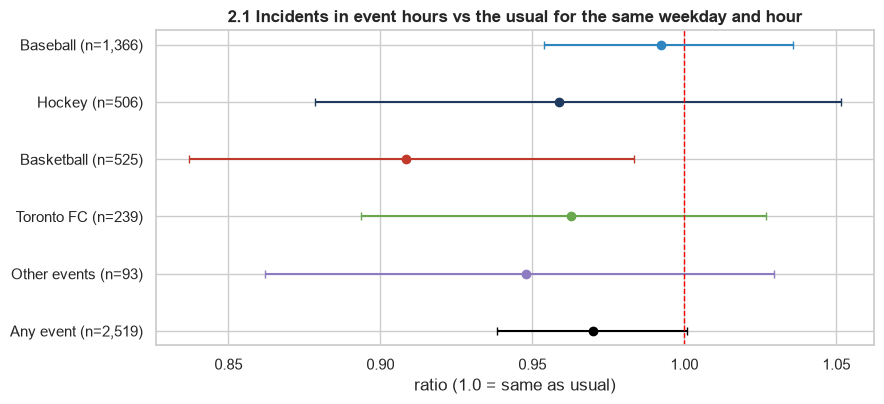

In [11]:
main_incidents = ratio_table(model_hours, "n_incidents")
fig, ax = plt.subplots(figsize=(9, 4.2))
forest(ax, main_incidents, "2.1 Incidents in event hours vs the usual for the same weekday and hour")
plt.tight_layout()
fmt(main_incidents)

**How to read it:** each dot is the ratio for a group of event hours; the line is its 95% interval; the red dashed line is "same as usual". `n` is the number of event hours.

**What stands out:**
- **Baseball is right at usual**: 0.99 (interval 0.95 to 1.04). A baseball hour has 7.79 incidents on average, against 7.85 expected.
- **Hockey, Toronto FC and other events are slightly below 1** (0.96, 0.96 and 0.95), but their intervals all include 1.0.
- **Basketball is the one group clearly below**: **0.91 (0.84 to 0.98)**, about 9% fewer incidents than usual.
- **Any event: 0.97 (0.94 to 1.00)**, so event hours have about 3% fewer incidents than usual, at most.

**What it means:** in this first look, **event hours do not have more incidents**. If anything they have a few fewer.

### 2.2 The same comparison for every outcome
Incidents, diversions, delay minutes, long delays (over 30 minutes), and incidents on near-venue routes vs other routes.

,Incidents,Diversions (MFDV),Delay minutes (capped),Long delays (> 30 min),"Incidents, near-venue routes","Incidents, other routes"
Baseball,0.99 (0.95-1.03),0.92 (0.83-1.04),0.95 (0.89-1.00),0.84 (0.75-0.94),1.01 (0.95-1.09),0.98 (0.95-1.03)
Hockey,0.96 (0.88-1.06),1.02 (0.83-1.25),0.94 (0.81-1.09),0.94 (0.78-1.13),0.94 (0.80-1.09),0.96 (0.87-1.05)
Basketball,0.91 (0.84-0.98),0.83 (0.69-0.95),0.80 (0.73-0.87),0.79 (0.67-0.92),0.89 (0.77-1.01),0.91 (0.84-0.99)
Toronto FC,0.96 (0.90-1.03),0.84 (0.64-1.09),0.90 (0.80-1.00),0.80 (0.63-0.98),1.00 (0.83-1.17),0.95 (0.88-1.02)
Other events,0.95 (0.87-1.03),0.98 (0.62-1.43),1.03 (0.90-1.18),1.05 (0.73-1.42),1.20 (1.05-1.38),0.93 (0.85-1.01)
Any event,0.97 (0.94-1.00),0.93 (0.86-1.01),0.93 (0.89-0.98),0.88 (0.81-0.95),0.99 (0.93-1.04),0.96 (0.93-1.00)


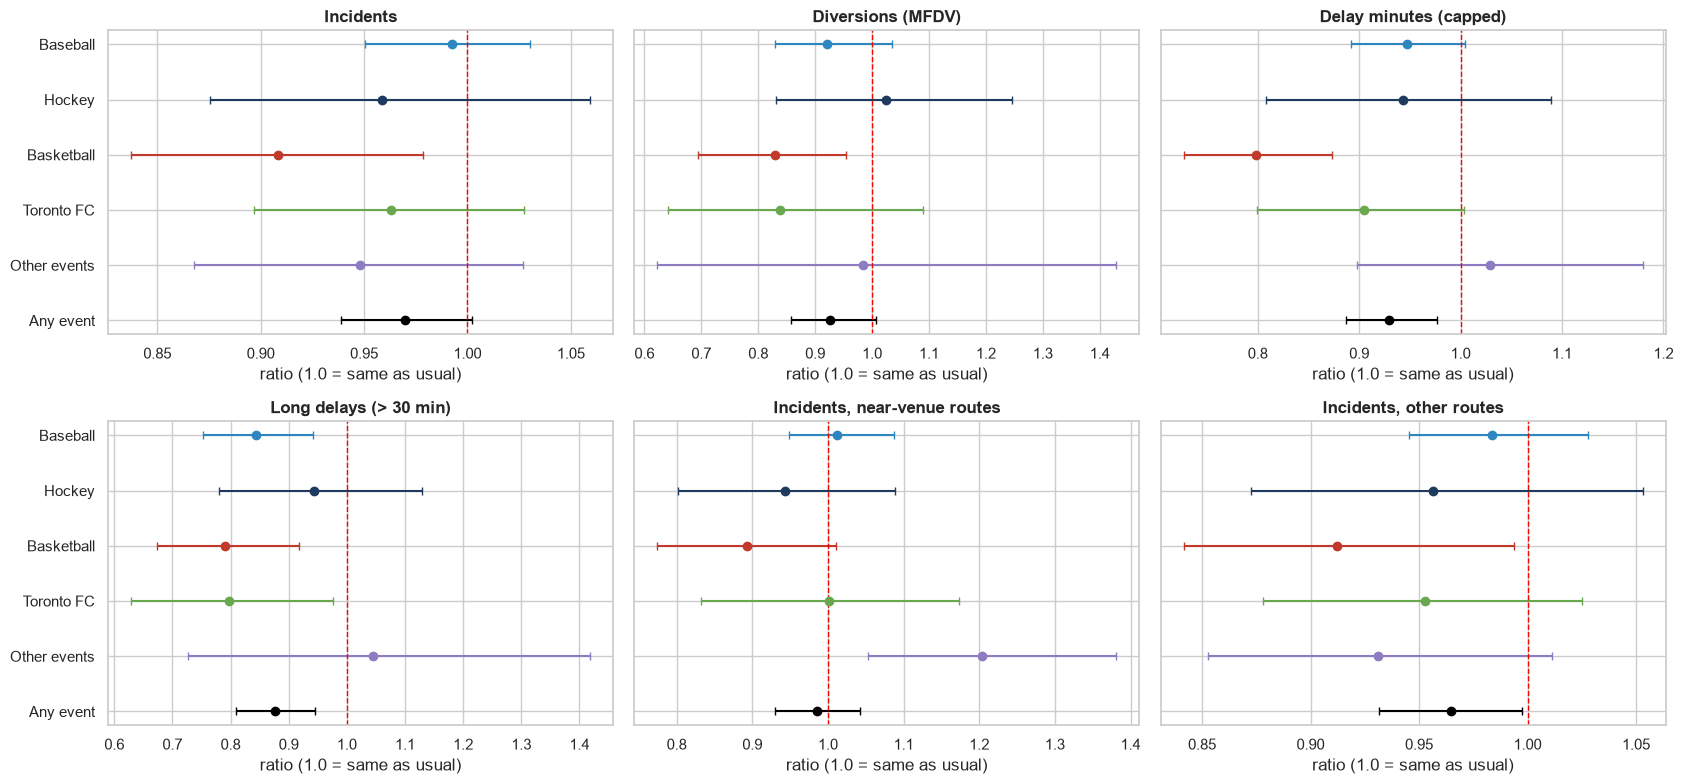

In [12]:
OUTCOMES = {"n_incidents": "Incidents", "n_diversion": "Diversions (MFDV)", "delay_minutes": "Delay minutes (capped)",
            "n_long_delays": "Long delays (> 30 min)", "n_near_venue": "Incidents, near-venue routes", "n_other_routes": "Incidents, other routes"}
outcome_tables = {col: ratio_table(model_hours, col) for col in OUTCOMES}

fig, axes = plt.subplots(2, 3, figsize=(17, 8), sharey=True)
for ax, (col, label) in zip(axes.ravel(), OUTCOMES.items()):
    forest(ax, outcome_tables[col], label, show_hours=False)
plt.tight_layout()

summary_ratio = pd.DataFrame({
    label: [f"{r:.2f} ({lo:.2f}-{hi:.2f})" for r, lo, hi in zip(t["ratio"], t["lo"], t["hi"])]
    for (col, label), t in zip(OUTCOMES.items(), outcome_tables.values())
}, index=outcome_tables["n_incidents"].index)
summary_ratio

**How to read it:** the same plot for six outcomes. The table repeats the numbers as "ratio (interval)".

**What stands out:**
- **Long delays (over 30 minutes) are lower in event hours**: any event **0.88 (0.81 to 0.95)**, baseball **0.84 (0.75 to 0.94)**, basketball 0.79 and Toronto FC 0.80.
- **Delay minutes** are lower too: any event 0.93 (0.89 to 0.98), basketball 0.80 (0.73 to 0.87).
- **Diversions** point down (any event 0.93, 0.86 to 1.01; basketball 0.83) but the intervals are wide.
- **Near-venue routes: no change for the sports** (baseball 1.01, Toronto FC 1.00, hockey 0.94, basketball 0.89), and **other city events are higher: 1.20 (1.05 to 1.38)**. This is the only value above 1, and it rests on 93 hours from 12 events.
- Other routes: about 0.96, the same as the total.

**A caution:** this plot has 36 intervals. With 95% intervals, two or three would miss 1.0 by chance. About ten do, almost all below 1, so this is more than chance, but single results should not be over-read.

**What it means:** event hours show **fewer long delays and less delay time**, not more. The one hint of a rise is other city events on near-venue routes.

### 2.3 Does the way we match change the answer?
Different definitions of "the same kind of hour". More detailed matching controls more, but leaves fewer comparison hours.

,Baseball,Hockey,Basketball,Toronto FC,Other events,Any event
weekday x hour (main),1366,506,525,239,93,2519
weekday type x hour,1366,506,525,239,93,2519
weekday x hour + calendar month,1363,473,512,233,93,2468
weekday x hour + coding period,1366,506,525,239,93,2519
weekday x hour + recent snow,1366,506,525,239,93,2519
weekday x hour + temperature band,1366,499,511,239,93,2498
weekday x hour + snow + holiday,1353,499,520,239,93,2494


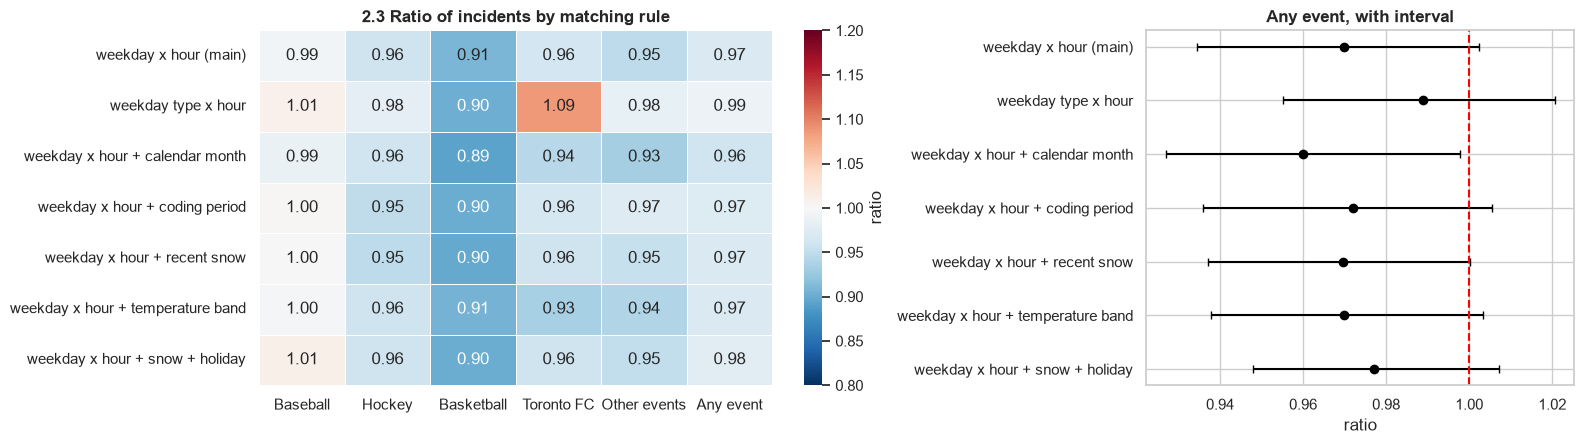

In [13]:
VARIANTS = {
    "weekday x hour (main)": SLOT168,
    "weekday type x hour": SLOT48,
    "weekday x hour + calendar month": ["weekday_slot", "month"],
    "weekday x hour + coding period": ["weekday_slot", "after_coding_change"],
    "weekday x hour + recent snow": ["weekday_slot", "snowy"],
    "weekday x hour + temperature band": ["weekday_slot", "temp_band"],
    "weekday x hour + snow + holiday": ["weekday_slot", "snowy", "is_holiday"],
}
variant_tables = {name: ratio_table(model_hours, "n_incidents", keys) for name, keys in VARIANTS.items()}
variant_ratio = pd.DataFrame({name: t["ratio"] for name, t in variant_tables.items()}).T
variant_hours = pd.DataFrame({name: t["hours"] for name, t in variant_tables.items()}).T.astype(int)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})
sns.heatmap(variant_ratio, annot=True, fmt=".2f", cmap="RdBu_r", center=1, vmin=0.8, vmax=1.2, linewidths=0.4, ax=axes[0], cbar_kws={"label": "ratio"})
axes[0].set(title="2.3 Ratio of incidents by matching rule", ylabel="")
any_event = pd.DataFrame({name: t.loc["Any event"] for name, t in variant_tables.items()}).T
y = np.arange(len(any_event))[::-1]
axes[1].errorbar(any_event["ratio"], y, xerr=[any_event["ratio"] - any_event["lo"], any_event["hi"] - any_event["ratio"]], fmt="o", color="black", capsize=3)
axes[1].axvline(1, color="red", ls="--")
axes[1].set_yticks(y)
axes[1].set_yticklabels(any_event.index)
axes[1].set(title="Any event, with interval", xlabel="ratio")
plt.tight_layout()
variant_hours

**How to read it:** the heatmap shows the ratio when "the same kind of hour" is defined in seven ways, from the simplest (weekday × hour) to more detailed (adding month, coding period, recent snow, temperature, holiday). Red is above 1, blue below. The right panel shows the interval for "any event". The table counts the event hours left in each case.

**What stands out:**
- **The answer barely moves.** Any event stays between **0.96 and 0.99**, and basketball between **0.89 and 0.91**, whichever rule we use.
- **Baseball is 0.99 to 1.01** in every version. Hockey is 0.95 to 0.98.
- **Toronto FC is the least stable** (0.93 to 1.09). With only two weekday types (weekday or weekend) × hour it is 1.09, but with each weekday × hour it is 0.96. It has just 239 event hours, mostly Saturdays.
- More detailed matching leaves fewer hours (for example hockey drops from 506 to 473 with month), but the picture is the same.

**What it means:** the result does not depend on how we match, so it is not an artefact of one choice.

### 2.4 Does the answer hold if we drop some hours?
Each row removes one kind of hour (the expected counts are recomputed on what is left). Numbers are ratios of incidents.

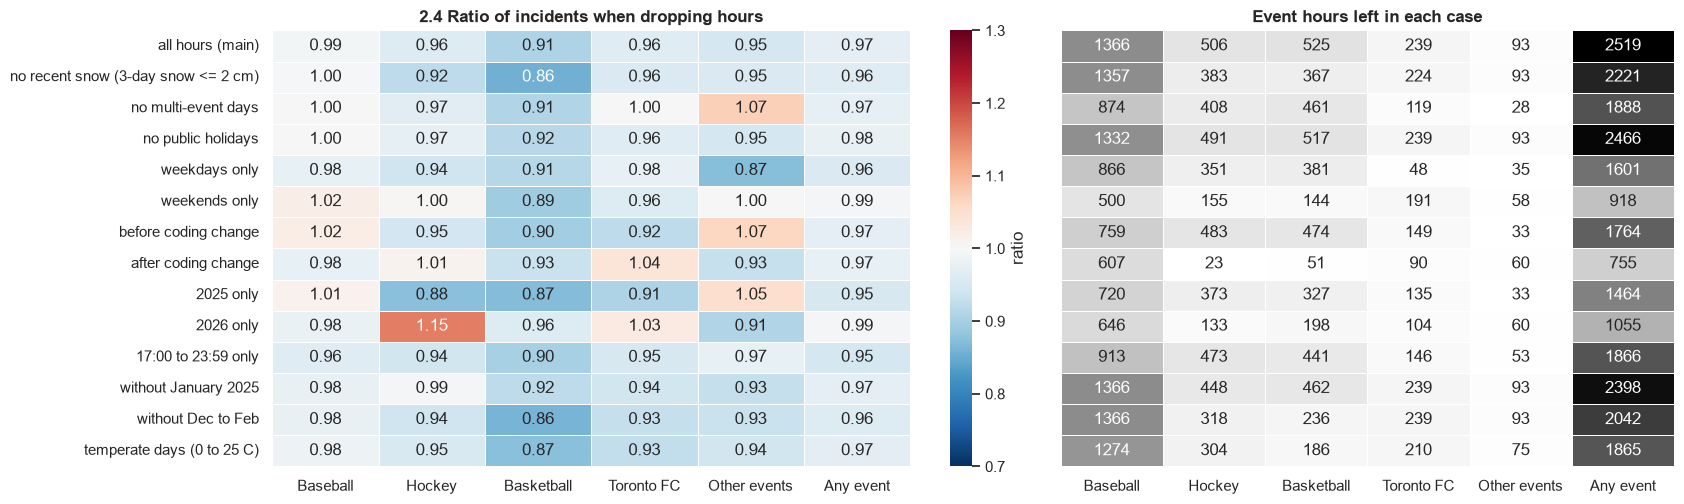

In [14]:
m = model_hours
SUBSETS = {
    "all hours (main)": pd.Series(True, index=m.index),
    "no recent snow (3-day snow <= 2 cm)": ~m["snowy"],
    "no multi-event days": ~m["multi_event_day"],
    "no public holidays": ~m["is_holiday"],
    "weekdays only": m["weekday_type"] == "weekday",
    "weekends only": m["weekday_type"] == "weekend",
    "before coding change": ~m["after_coding_change"],
    "after coding change": m["after_coding_change"],
    "2025 only": m["year"] == 2025,
    "2026 only": m["year"] == 2026,
    "17:00 to 23:59 only": m["hour"].between(17, 23),
    "without January 2025": ~((m["year"] == 2025) & (m["month"] == 1)),
    "without Dec to Feb": ~m["month"].isin([12, 1, 2]),
    "temperate days (0 to 25 C)": m["temp_mean_c"].between(0, 25),
}
subset_tables = {name: ratio_table(m[mask], "n_incidents") for name, mask in SUBSETS.items()}
subset_ratio = pd.DataFrame({name: t["ratio"] for name, t in subset_tables.items()}).T
subset_hours = pd.DataFrame({name: t["hours"] for name, t in subset_tables.items()}).T.astype(int)

fig, axes = plt.subplots(1, 2, figsize=(17, 5.2), gridspec_kw={"width_ratios": [1.3, 1]})
sns.heatmap(subset_ratio, annot=True, fmt=".2f", cmap="RdBu_r", center=1, vmin=0.7, vmax=1.3, linewidths=0.4, ax=axes[0], cbar_kws={"label": "ratio"})
axes[0].set(title="2.4 Ratio of incidents when dropping hours", ylabel="")
sns.heatmap(subset_hours, annot=True, fmt="d", cmap="Greys", linewidths=0.4, ax=axes[1], cbar=False)
axes[1].set(title="Event hours left in each case", ylabel="")
axes[1].set_yticklabels([])
plt.tight_layout()

**How to read it:** each row drops one kind of hour and recomputes the ratio on what is left. The right-hand table shows how many event hours remain.

**What stands out:**
- **Any event stays at 0.95 to 0.99** in all 14 cases, and basketball at 0.86 to 0.96. Dropping snow days, holidays, winter, January 2025 or multi-event days does not create an increase.
- **Hockey is different in each year**: **0.88 in 2025 and 1.15 in 2026**. After the coding change it is 1.01, but on only 23 event hours, so this is thin.
- **Other events** are 0.87 on weekdays and 1.00 on weekends, and 1.07 when multi-event days are dropped (28 hours): small and uncertain.
- Basketball is lowest without recent snow (0.86) and without Dec to Feb (0.86). It is less low in 2026 (0.96).

**What it means:** the main finding (no rise) holds when we remove the usual suspects. Hockey in 2026 and the small groups are the shakiest.

### 2.5 Hour by hour around the start
Each event hour is placed by its distance from the start time of the event (`-2` = two hours before start, `0` = the hour of the start,
`+3` = three hours after; sports games are assumed to last 3 hours). Only groups with a start time are shown. The shaded band is the 95% interval.

,offset,hours,observed,expected,ratio,lo,hi
0,-2,338,10.222,10.766,0.949,0.905,0.998
1,-1,341,9.718,10.089,0.963,0.911,1.013
2,0,341,7.871,8.120,0.969,0.915,1.018
3,1,341,7.431,7.637,0.973,0.918,1.026
4,2,341,6.938,7.187,0.965,0.913,1.021
5,3,341,6.000,6.397,0.938,0.872,1.005
6,4,341,5.340,5.444,0.981,0.912,1.049
7,5,252,5.183,4.903,1.057,0.977,1.140


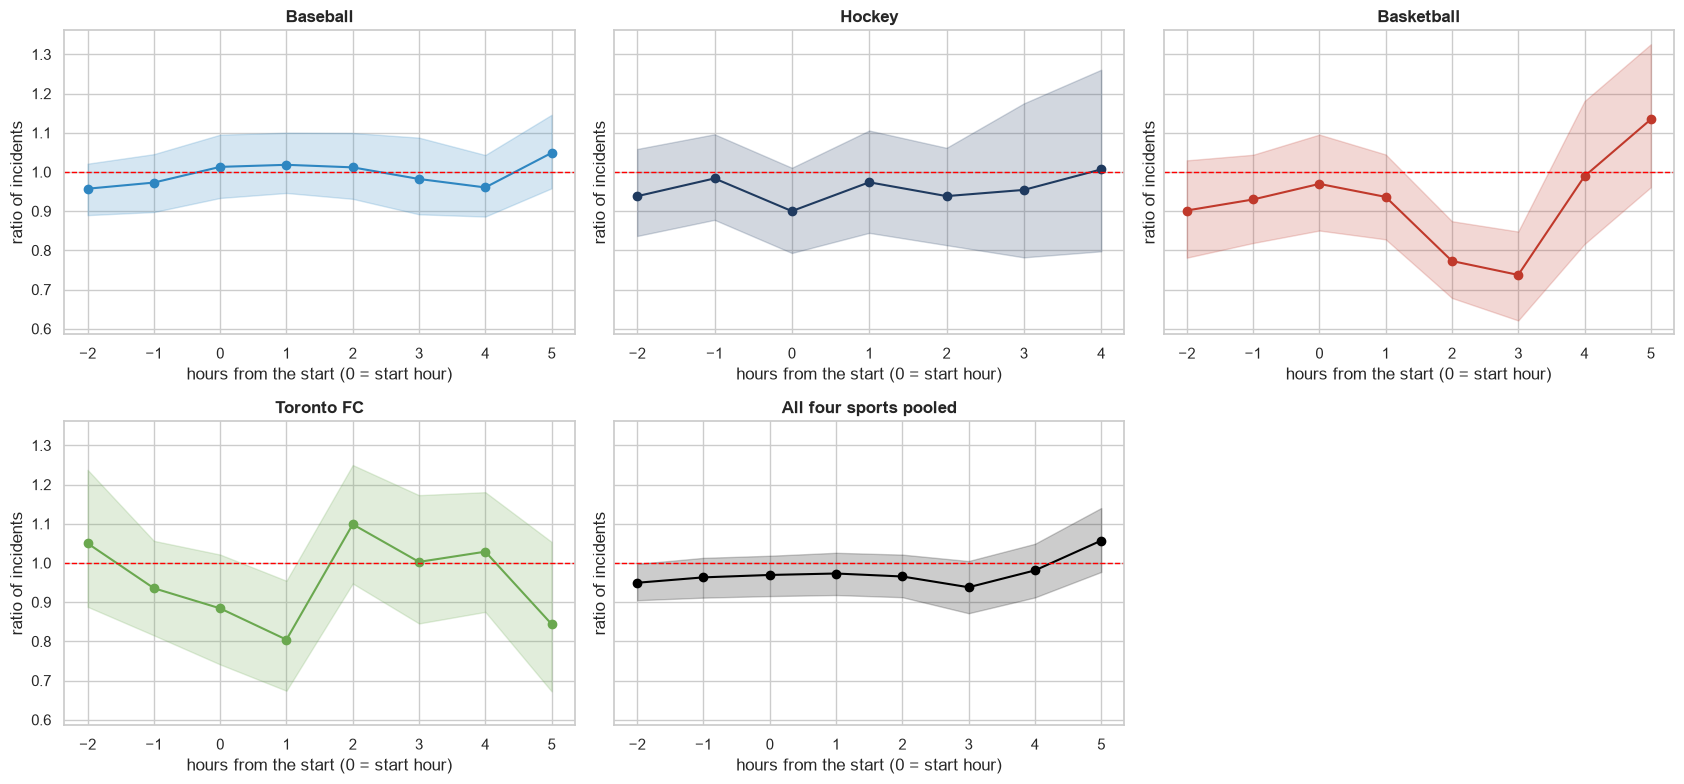

In [15]:
timed_info = timed.set_index("event_id")[["start", "event_name", "event_type", "venue"]]
ev_hours = window_rows.join(timed_info[["start"]], on="event_id")
ev_hours["offset"] = np.floor((ev_hours["datetime"] - ev_hours["start"].dt.floor("h")) / pd.Timedelta(hours=1)).astype(int)
ev_hours["start_hour"] = ev_hours["start"].dt.hour
ATTRS = ["datetime", "evening_date", "weekday_type", "month", "hour", "after_coding_change"]


def event_rows(outcome, keys=SLOT168, df=None):
    """One row per event-hour (an hour inside two windows appears twice), with observed, expected and attributes."""
    df = model_hours if df is None else df
    d = add_expected(df, keys, outcome)[ATTRS + [outcome, "expected"]]
    return ev_hours.merge(d, on="datetime", how="inner")


def ratio_by(rows, outcome, by, cluster="event_id"):
    out = []
    for key, g in rows.groupby(by, observed=True):
        out.append({**(dict(zip(by, key)) if isinstance(by, list) else {by: key}), **summarise_ratio(g.assign(cluster=g[cluster]), outcome)})
    return pd.DataFrame(out)


rows_inc = event_rows("n_incidents")
SPORTS = ["mlb", "nhl", "nba", "mls"]
SPORT_NAMES = {"mlb": "Baseball", "nhl": "Hockey", "nba": "Basketball", "mls": "Toronto FC", "other": "Other events"}
by_offset = ratio_by(rows_inc, "n_incidents", ["group", "offset"])
pooled_offset = ratio_by(rows_inc[rows_inc["group"].isin(SPORTS)], "n_incidents", ["offset"])

fig, axes = plt.subplots(2, 3, figsize=(17, 8), sharey=True)
panels = [(SPORT_NAMES[g], by_offset[by_offset["group"] == g]) for g in SPORTS] + [("All four sports pooled", pooled_offset)]
for ax, (title, t) in zip(axes.ravel(), panels):
    t = t[t["hours"] >= 20]
    color = GROUP_COLORS.get(title, "black")
    ax.fill_between(t["offset"], t["lo"], t["hi"], color=color, alpha=0.2)
    ax.plot(t["offset"], t["ratio"], marker="o", color=color)
    ax.axhline(1, color="red", ls="--", lw=1)
    ax.set(title=title, xlabel="hours from the start (0 = start hour)", ylabel="ratio of incidents")
axes[1, 2].axis("off")
plt.tight_layout()
pooled_offset.round(3)

**How to read it:** each panel follows one sport hour by hour from 2 hours before the start (`-2`) to 5 hours after (`+5`). The line is the ratio, and the band is the 95% interval. Points with fewer than 20 hours are hidden. The last table is the pooled series.

**What stands out:**
- **Pooled over the four sports, every hour from -2 to +4 is at 0.94 to 0.98**, always slightly under 1. **There is no jump at the start time or at the end**.
- **Baseball is flat around 1.0** (0.96 to 1.05) in every hour.
- **Basketball dips two and three hours after the start** (0.77 and 0.74), when the game is on.
- **Toronto FC** wiggles (0.80 to 1.10) but has only about 30 games per offset.
- The last hour (+5, after midnight) is 1.06 (0.98 to 1.14) pooled, based on 252 hours: a small, uncertain rise.

**What it means:** there is no sign of extra trouble when fans arrive or leave. A pattern of "up before, down during" does not appear either, apart from basketball.

### 2.6 By clock hour
The same ratio, by hour of the day instead of distance from the start. Cells with fewer than 20 event hours are left blank.

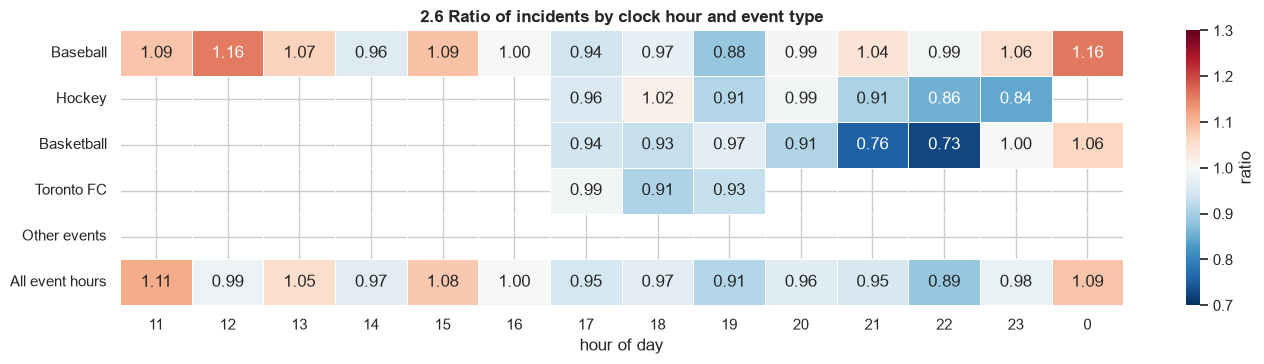

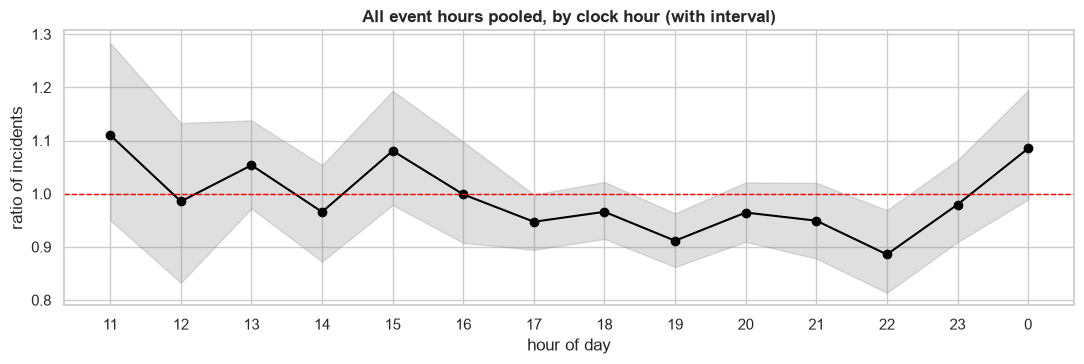

In [16]:
by_clock = ratio_by(rows_inc, "n_incidents", ["group", "hour"])
clock_order = list(range(11, 24)) + [0]
grid = by_clock[by_clock["hours"] >= 20].pivot(index="group", columns="hour", values="ratio").reindex(index=list(SPORT_NAMES), columns=clock_order)
grid.index = [SPORT_NAMES[g] for g in grid.index]
all_sports = ratio_by(rows_inc, "n_incidents", ["hour"]).set_index("hour")
grid.loc["All event hours"] = all_sports["ratio"].reindex(clock_order)

fig, ax = plt.subplots(figsize=(14, 3.8))
sns.heatmap(grid, annot=True, fmt=".2f", cmap="RdBu_r", center=1, vmin=0.7, vmax=1.3, linewidths=0.4, ax=ax, cbar_kws={"label": "ratio"})
ax.set(title="2.6 Ratio of incidents by clock hour and event type", xlabel="hour of day", ylabel="")
plt.tight_layout()

hours_by_clock = all_sports["ratio"].to_frame("ratio").assign(lo=all_sports["lo"], hi=all_sports["hi"]).reindex(clock_order)
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.fill_between(range(len(clock_order)), hours_by_clock["lo"], hours_by_clock["hi"], color="gray", alpha=0.25)
ax.plot(range(len(clock_order)), hours_by_clock["ratio"], marker="o", color="black")
ax.axhline(1, color="red", ls="--", lw=1)
ax.set_xticks(range(len(clock_order)))
ax.set_xticklabels(clock_order)
ax.set(title="All event hours pooled, by clock hour (with interval)", xlabel="hour of day", ylabel="ratio of incidents")
plt.tight_layout()

**How to read it:** the heatmap shows the ratio for each sport and clock hour (blank if under 20 event hours). The line below is all event hours pooled, with its interval.

**What stands out:**
- **Pooled, most hours are 0.89 to 1.11 and cross 1.0**. The ones that do not: **7 pm (0.91)** and **10 pm (0.89)**, both below 1.
- **Basketball late in the evening** (9 and 10 pm) is **0.76 and 0.73**, when games are ending, and **hockey at 10 and 11 pm** is 0.86 and 0.84.
- **Baseball at noon** has a few cells above 1 (11 am, 12 pm and 3 pm at 1.09 to 1.16), but only the **midnight hour (1.16)** has an interval clear of 1 above, and it has few games. **Baseball at 7 pm is clearly below 1 (0.88)**.

**What it means:** the lower ratios are in the **late evening of indoor games** (hockey and basketball). Nothing suggests extra incidents in any hour of the day.

### 2.7 Splits: weekday or weekend, season, start time
Does the ratio differ between weekdays and weekends, cold and warm months, and day or evening starts? (Intervals resample events.)

hours  ratio
           group                                    
day_type   mlb   weekday                  866   0.98
                 weekend                  500   1.02
           mls   weekday                   48   0.98
                 weekend                  191   0.96
           nba   weekday                  381   0.91
                 weekend                  144   0.89
           nhl   weekday                  351   0.94
                 weekend                  155   1.00
           other weekday                   35   0.87
                 weekend                   58   1.00
season     mlb   cold months (Nov-Mar)     86   0.99
                 warm months (Apr-Oct)   1280   0.99
           mls   cold months (Nov-Mar)     30   0.79
                 warm months (Apr-Oct)    209   0.99
           nba   cold months (Nov-Mar)    434   0.90
                 warm months (Apr-Oct)     91   0.93
           nhl   cold months (Nov-Mar)    326   1.00
                 warm months (Apr-Oct)    180   0.89
           other warm months (Apr-Oct)     86   0.94
start_time mlb   starts 19:00 or later    761   0.99
                 starts before 17:00      597   1.00
           mls   starts 19:00 or later    120   0.97
                 starts before 17:00      112   0.96
           nba   starts 17-18              79   0.86
                 starts 19:00 or later    400   0.90
                 starts before 17:00       46   1.06
           nhl   starts 19:00 or later    470   0.92
           other starts before 17:00       64   0.92

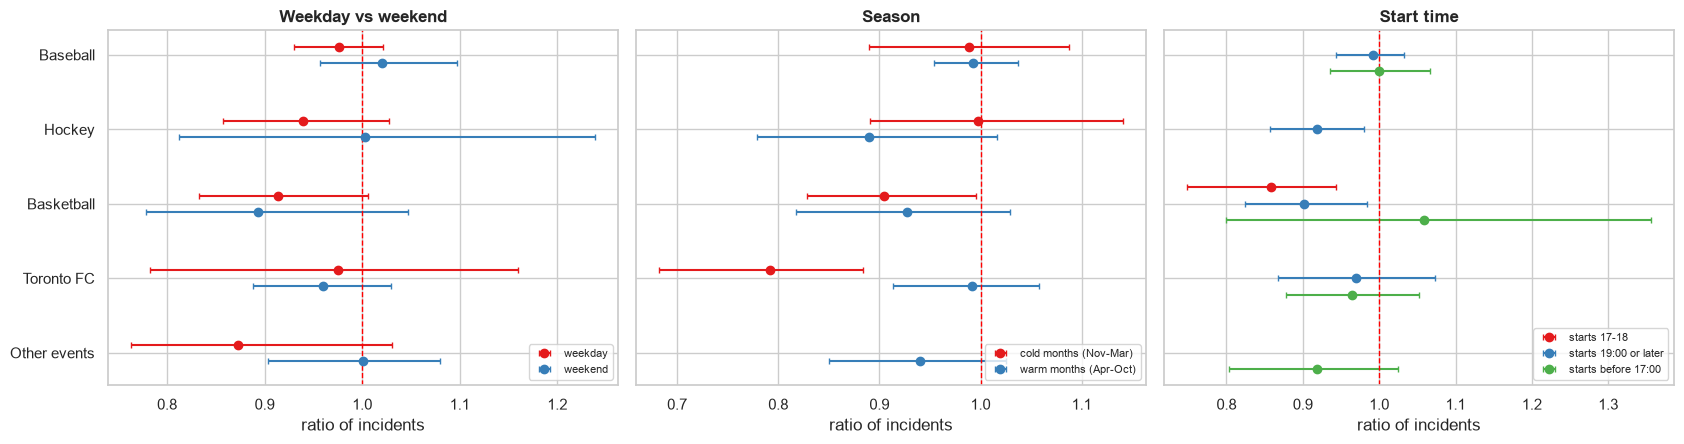

In [17]:
rows_split = rows_inc.assign(
    day_type=lambda t: t["weekday_type"],
    season=lambda t: np.where(t["month"].isin([11, 12, 1, 2, 3]), "cold months (Nov-Mar)", "warm months (Apr-Oct)"),
    start_time=lambda t: np.where(t["start_hour"] < 17, "starts before 17:00", np.where(t["start_hour"] >= 19, "starts 19:00 or later", "starts 17-18")),
)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), sharey=True)
split_tables = {}
for ax, col, title in zip(axes, ["day_type", "season", "start_time"], ["Weekday vs weekend", "Season", "Start time"]):
    t = ratio_by(rows_split, "n_incidents", ["group", col])
    t = t[t["hours"] >= 30]
    split_tables[col] = t
    values = sorted(t[col].unique())
    palette = sns.color_palette("Set1", len(values))
    for j, value in enumerate(values):
        sub = t[t[col] == value]
        ypos = [list(SPORT_NAMES).index(g) + (j - (len(values) - 1) / 2) * 0.22 for g in sub["group"]]
        ax.errorbar(sub["ratio"], ypos, xerr=[sub["ratio"] - sub["lo"], sub["hi"] - sub["ratio"]], fmt="o", color=palette[j], capsize=2, label=value)
    ax.axvline(1, color="red", ls="--", lw=1)
    ax.set_yticks(range(len(SPORT_NAMES)))
    ax.set_yticklabels(SPORT_NAMES.values())
    ax.invert_yaxis()
    ax.legend(fontsize=8, loc="lower right")
    ax.set(title=title, xlabel="ratio of incidents")
plt.tight_layout()
pd.concat({col: t.set_index(["group", col])[["hours", "ratio"]].round(2) for col, t in split_tables.items()})

**How to read it:** each panel splits the ratio for each sport by one extra factor (colours). Intervals resample events. Cells with fewer than 30 hours are hidden.

**What stands out:**
- **Weekday vs weekend:** baseball is 0.98 on weekdays and 1.02 on weekends, hockey 0.94 and 1.00, basketball 0.91 and 0.89, Toronto FC 0.98 and 0.96. **Other events are 0.87 on weekdays and 1.00 on weekends.** The intervals overlap.
- **Season:** **Toronto FC in the cold months is 0.79** (0.68 to 0.88, only 30 hours), against 0.99 in warm months. **Hockey in the warm months (the playoffs) is 0.89**, against 1.00 in the cold months.
- **Start time:** baseball is 1.00 and 0.99 whether games start before 5 pm or after 7 pm. Basketball is 0.86 and 0.90 for evening starts. Hockey (almost all 7 pm) is 0.92.

**What it means:** no subgroup shows a rise. The few lower values are in small groups, so they are leads and not findings.

### 2.8 By cause group
Incidents are split into the four cause groups from notebook 02. Equipment and operator problems are about the buses and staff; miscellaneous includes diversions.

,Equipment,Miscellaneous,Operator,Security
Baseball,0.96 (0.90-1.03),1.02 (0.96-1.08),0.99 (0.93-1.05),1.02 (0.94-1.09)
Hockey,0.98 (0.89-1.08),0.92 (0.80-1.06),1.02 (0.90-1.16),0.87 (0.75-0.97)
Basketball,0.96 (0.86-1.07),0.86 (0.75-0.98),0.98 (0.86-1.12),0.77 (0.67-0.87)
Toronto FC,0.97 (0.87-1.08),1.05 (0.91-1.22),0.81 (0.70-0.93),1.07 (0.91-1.22)
Other events,0.95 (0.81-1.11),0.92 (0.76-1.06),0.97 (0.76-1.21),0.97 (0.63-1.34)
Any event,0.96 (0.92-1.01),0.98 (0.92-1.02),0.97 (0.92-1.02),0.94 (0.89-1.00)


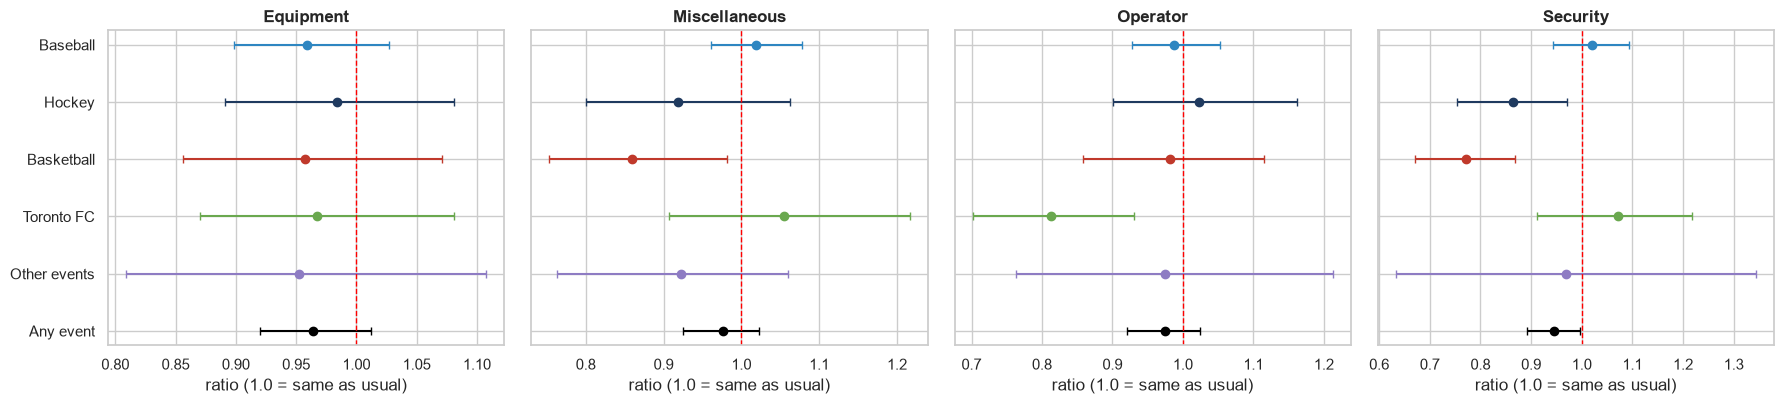

In [18]:
causes = pd.read_csv(PROCESSED / "incidents.csv", parse_dates=["datetime"], usecols=["datetime", "cause_group"])
cause_hourly = (pd.crosstab(causes["datetime"].dt.floor("h"), causes["cause_group"])
                .reindex(columns=["Equipment", "Miscellaneous", "Operator", "Security"], fill_value=0)
                .add_prefix("n_cause_").rename_axis(index="datetime", columns=None).reset_index())
model_hours = model_hours.drop(columns=[c for c in model_hours.columns if c.startswith("n_cause_")]).merge(cause_hourly, on="datetime", how="left", validate="one_to_one")
cause_cols = [c for c in model_hours.columns if c.startswith("n_cause_")]
model_hours[cause_cols] = model_hours[cause_cols].fillna(0).astype(int)

cause_tables = {c.replace("n_cause_", ""): ratio_table(model_hours, c) for c in cause_cols}
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2), sharey=True)
for ax, (name, t) in zip(axes, cause_tables.items()):
    forest(ax, t, name, show_hours=False)
plt.tight_layout()
pd.DataFrame({name: [f"{r:.2f} ({lo:.2f}-{hi:.2f})" for r, lo, hi in zip(t["ratio"], t["lo"], t["hi"])] for name, t in cause_tables.items()}, index=cause_tables["Equipment"].index)

**How to read it:** the same plot, per cause group.

**What stands out:**
- **Baseball is about 1.0 in every group** (0.96 to 1.02).
- **Security incidents are lower during hockey (0.87) and basketball (0.77)**, and any event is 0.94 (0.89 to 1.00).
- **Miscellaneous is lower for basketball (0.86)**, and operator problems are lower for Toronto FC (0.81).
- **Equipment** is about 0.96 for everything.

**What it means:** the dip in indoor-game hours comes mostly from fewer **security and miscellaneous** incidents. These are the groups that peak at night (see 02_eda, Step 3), so the lower ratio may be partly about **who is on the bus in the evening**, not about events causing a drop. The regression will help sort this out.

### 2.9 Near-venue routes vs other routes, around the start
Pooled over the four sports. Near-venue routes have few incidents per hour, so their intervals are wide.

,hours,observed,expected,ratio,95% interval
Baseball,1366,0.69,0.68,1.013,0.94 to 1.08
Toronto FC,239,0.79,0.79,1.001,0.85 to 1.15
Basketball,525,0.53,0.60,0.893,0.77 to 1.02
Hockey,506,0.60,0.64,0.944,0.80 to 1.08
Other events,93,0.91,0.76,1.204,1.07 to 1.39


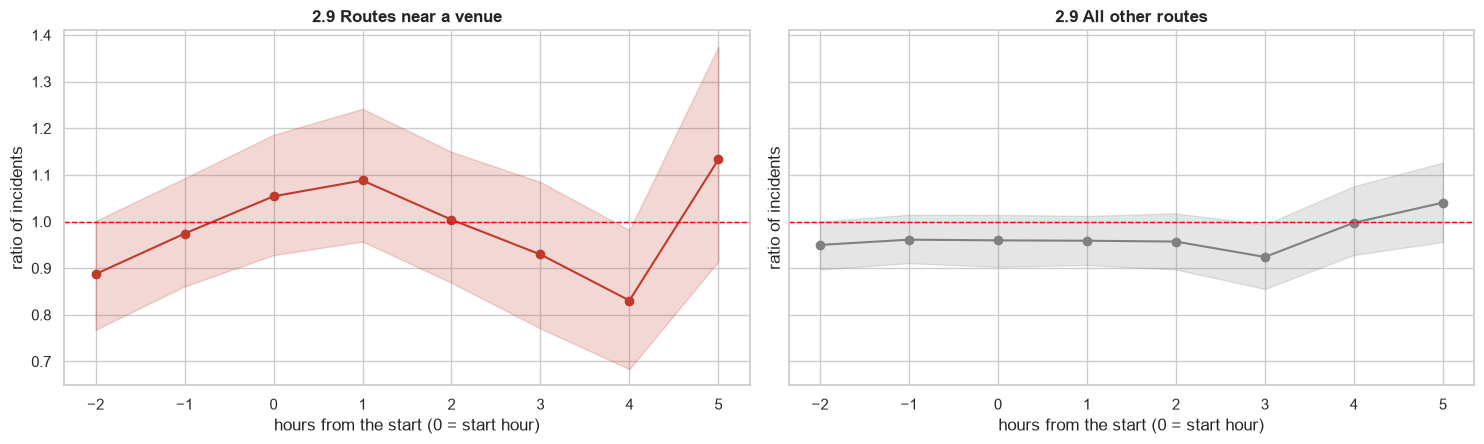

In [19]:
near_rows = event_rows("n_near_venue")
other_rows = event_rows("n_other_routes")
sports_only = lambda r: r[r["group"].isin(SPORTS)]
near_offset = ratio_by(sports_only(near_rows), "n_near_venue", ["offset"])
other_offset = ratio_by(sports_only(other_rows), "n_other_routes", ["offset"])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), sharey=True)
for ax, (title, t, color) in zip(axes, [("Routes near a venue", near_offset, "#c0392b"), ("All other routes", other_offset, "gray")]):
    t = t[t["hours"] >= 20]
    ax.fill_between(t["offset"], t["lo"], t["hi"], color=color, alpha=0.2)
    ax.plot(t["offset"], t["ratio"], marker="o", color=color)
    ax.axhline(1, color="red", ls="--", lw=1)
    ax.set(title=f"2.9 {title}", xlabel="hours from the start (0 = start hour)", ylabel="ratio of incidents")
plt.tight_layout()

near_by_sport = ratio_by(near_rows, "n_near_venue", ["group"]).set_index("group")
near_by_sport.index = [SPORT_NAMES[g] for g in near_by_sport.index]
fmt(near_by_sport)

**How to read it:** the ratio around the start for routes near a venue (left) and all other routes (right), pooled over the four sports. The table below gives the near-venue ratio by sport.

**What stands out:**
- **Near-venue routes**: below usual two hours before the start (0.89, interval 0.77 to 1.00), a little above at the start and one hour after (1.05 and 1.09), and low four hours after (0.83). **Every interval except the last includes 1.0**, so there is no clear pattern.
- **Other routes** are flat at 0.92 to 1.0.
- **By sport**, near-venue routes are baseball 1.01, Toronto FC 1.00, hockey 0.94 and basketball 0.89. **Other events: 1.20 (1.07 to 1.39)**.

**What it means:** routes near the venue behave like the rest of the network during sports games. The only increase is during the parades, festivals and World Cup matches (93 hours, 12 events), which are too few for firm conclusions.

### 2.10 Event by event
One ratio per event window: incidents in all its hours vs the expected number for the same hours. This shows how much events differ from each other, and which ones stand out.

Spread of event ratios by group (standard deviation): {'mlb': 0.26, 'mls': 0.2, 'nba': 0.29, 'nhl': 0.38, 'other': 0.15}


,event_name,date,hours,observed,expected,ratio
event_id,,,,,,
nhl_2025020819,Maple Leafs vs COL,2026-01-25,8,169,54.9,3.08
mlb_777408,Blue Jays vs Chicago White Sox,2025-06-22,8,156,54.9,2.84
nba_401810445,Toronto Raptors vs LA Clippers,2026-01-16,8,132,60.2,2.19
nhl_2025021094,Maple Leafs vs CAR,2026-03-20,7,95,55.9,1.70
nba_401810296,Toronto Raptors vs Golden State Warriors,2025-12-28,8,94,55.7,1.69
mlb_777837,Blue Jays vs San Diego Padres,2025-05-21,8,98,60.7,1.62
nba_401810306,Toronto Raptors vs Orlando Magic,2025-12-29,8,79,49.2,1.61
nhl_2024030115,Maple Leafs vs OTT,2025-04-29,7,84,53.3,1.58
nhl_2024030112,Maple Leafs vs OTT,2025-04-22,8,22,56.7,0.39


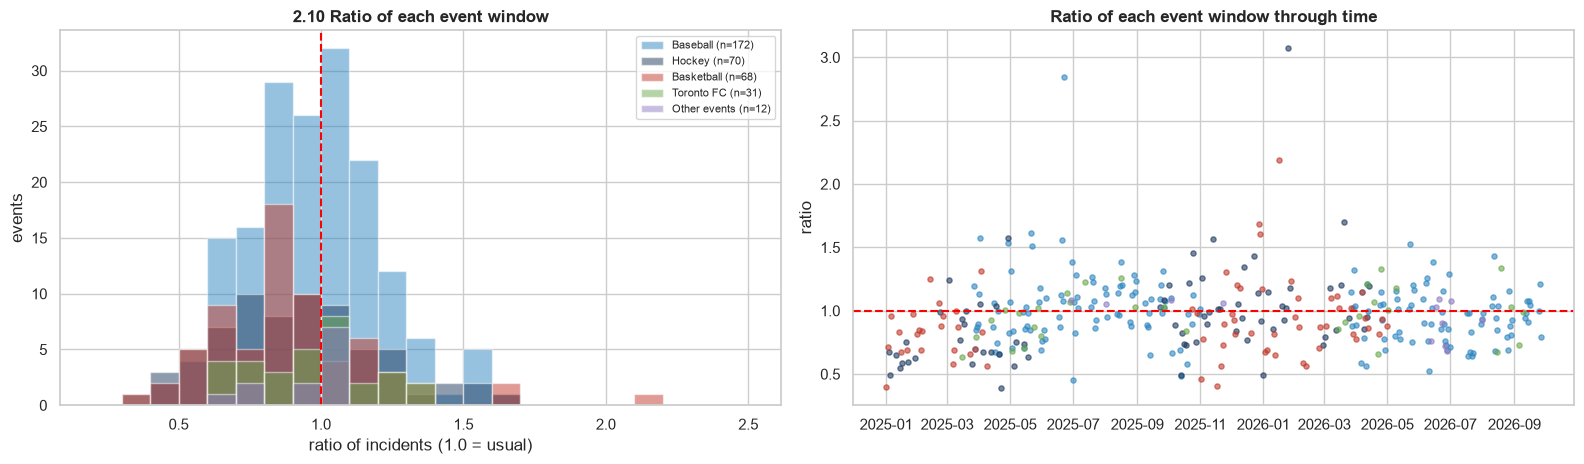

In [20]:
event_level = (
    rows_inc[rows_inc["expected"].notna()].groupby("event_id")
    .agg(group=("group", "first"), observed=("n_incidents", "sum"), expected=("expected", "sum"), hours=("datetime", "size"), date=("evening_date", "first"))
    .assign(ratio=lambda t: t["observed"] / t["expected"])
    .join(timed_info[["event_name"]])
)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for g in SPORT_NAMES:
    sub = event_level[event_level["group"] == g]
    axes[0].hist(sub["ratio"], bins=np.arange(0.2, 2.6, 0.1), alpha=0.5, label=f"{SPORT_NAMES[g]} (n={len(sub)})", color=GROUP_COLORS[SPORT_NAMES[g]])
axes[0].axvline(1, color="red", ls="--")
axes[0].set(title="2.10 Ratio of each event window", xlabel="ratio of incidents (1.0 = usual)", ylabel="events")
axes[0].legend(fontsize=8)
for g in SPORT_NAMES:
    sub = event_level[event_level["group"] == g]
    axes[1].scatter(sub["date"], sub["ratio"], s=14, alpha=0.6, color=GROUP_COLORS[SPORT_NAMES[g]], label=SPORT_NAMES[g])
axes[1].axhline(1, color="red", ls="--")
axes[1].set(title="Ratio of each event window through time", xlabel="", ylabel="ratio")
plt.tight_layout()
print("Spread of event ratios by group (standard deviation):", event_level.groupby("group")["ratio"].std().round(2).to_dict())
pd.concat([event_level.nlargest(8, "ratio"), event_level.nsmallest(5, "ratio")])[["event_name", "date", "hours", "observed", "expected", "ratio"]].round({"observed": 1, "expected": 1, "ratio": 2})

**How to read it:** each event window gets its own ratio (observed ÷ expected incidents over its hours). The histogram shows how they spread, the right chart puts them through time, and the table lists the highest and lowest events.

**What stands out:**
- **Events differ a lot from each other**: the typical spread (standard deviation) of a ratio is 0.26 for baseball, 0.29 for basketball and 0.38 for hockey. The middle of the distribution is close to 1, but the tails are long.
- **The highest are weather days:** the Leafs vs Colorado game on **2026-01-25 (3.08: 169 incidents vs 55 expected)** was during the biggest snowfall (46 cm), and the Raptors vs Clippers game on **2026-01-16 (2.19)** was the day after the 2026-01-15 storm. The Blue Jays game on 2025-06-22 (2.84) is also very high; we have not looked into why.
- **The lowest are holidays:** the Raptors on **New Year's Day 2025 (0.40)** and the Blue Jays on **Canada Day 2025 (0.45)**.
- Median ratios by group are 0.98 (baseball), 0.87 (basketball) and 0.92 (hockey).

**What it means:** a single event's ratio mostly reflects the weather and calendar of that day, not the event. This is why the regression must control for weather and holidays, and why conclusions need many events.

### 2.11 What does chance look like? Fake events
If events did nothing, the ratio would still not be exactly 1.0. To see how far chance can move it, each real event is moved to a **random day with no event and the same weekday**, keeping the same hours.
This is repeated 1,000 times. The histogram shows the ratios that fake events give; the red line is the real ratio. A real ratio inside the fake range is not distinguishable from chance.

/var/folders/5_/_tpr1gmn6w1cd36rvyrryg3m0000gn/T/ipykernel_92247/2352715546.py:10: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  cand = np.full((7, max_len), np.datetime64("NaT"), dtype="datetime64[ns]")


,real ratio,fake: mean,fake 2.5%,fake 97.5%,share of fake as far from 1
group,,,,,
Baseball,0.992,0.998,0.955,1.045,0.755
Hockey,0.959,0.999,0.927,1.080,0.283
Basketball,0.909,0.996,0.930,1.068,0.011
Toronto FC,0.963,0.986,0.886,1.093,0.488
Other events,0.948,0.997,0.845,1.169,0.499
All events,0.967,0.997,0.967,1.027,0.044


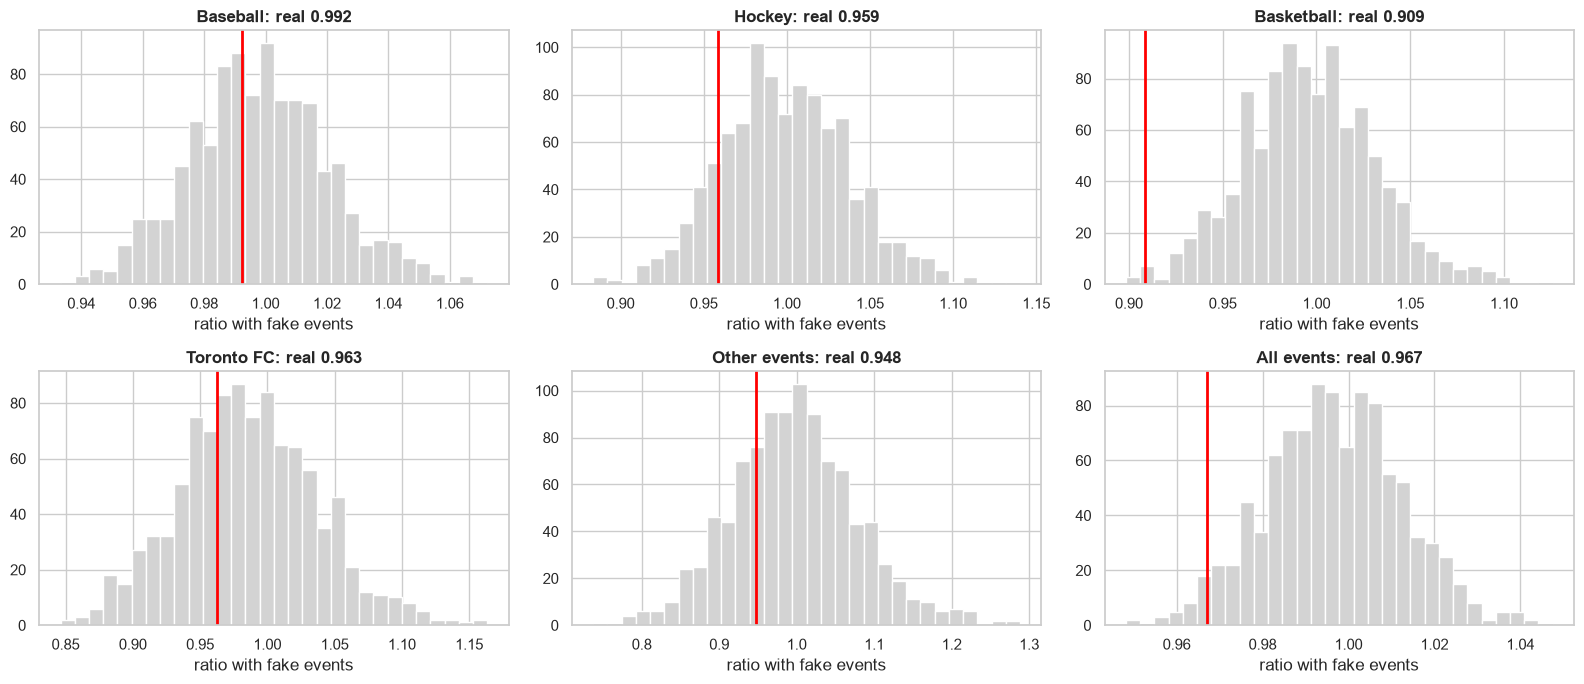

In [21]:
mh_idx = pd.DatetimeIndex(model_hours["datetime"])
expected_all = add_expected(model_hours, SLOT168, "n_incidents")["expected"].to_numpy()
observed_all = model_hours["n_incidents"].to_numpy()
in_window_all = model_hours["in_event_window"].to_numpy()

event_days = set(model_hours.loc[model_hours["in_event_window"], "evening_date"])
free_days = pd.Series(sorted(set(model_hours["evening_date"]) - event_days))
free_by_weekday = [free_days[free_days.dt.day_of_week == k].to_numpy() for k in range(7)]
max_len = max(len(a) for a in free_by_weekday)
cand = np.full((7, max_len), np.datetime64("NaT"), dtype="datetime64[ns]")
cand_len = np.array([len(a) for a in free_by_weekday])
for k, a in enumerate(free_by_weekday):
    cand[k, :len(a)] = a

ev = ev_hours.assign(base_date=lambda t: t["start"].dt.normalize()).merge(
    model_hours[["datetime"]].assign(row=np.arange(len(model_hours))), on="datetime", how="inner")
ev["offset_h"] = ((ev["datetime"] - ev["base_date"]) / pd.Timedelta(hours=1)).astype(int)
windows = ev.drop_duplicates("event_id")[["event_id", "base_date", "group"]].reset_index(drop=True)
windows["weekday"] = windows["base_date"].dt.day_of_week
win_index = windows.reset_index().set_index("event_id")["index"]
hour_win = ev["event_id"].map(win_index).to_numpy()
hour_off = ev["offset_h"].to_numpy()
hour_group = ev["group"].to_numpy()
group_names = list(SPORT_NAMES)

# real ratios on the same basis (one row per event-hour)
real = {}
for g in group_names + ["all"]:
    sel = np.ones(len(ev), bool) if g == "all" else hour_group == g
    real[g] = observed_all[ev["row"].to_numpy()[sel]].sum() / expected_all[ev["row"].to_numpy()[sel]].sum()

n_draws = 1000
fake = {g: np.empty(n_draws) for g in group_names + ["all"]}
wd = windows["weekday"].to_numpy()
for b in range(n_draws):
    pick = (RNG.random(len(windows)) * cand_len[wd]).astype(int)
    new_base = cand[wd, pick]
    target = new_base[hour_win] + hour_off.astype("timedelta64[h]")
    pos = mh_idx.get_indexer(pd.DatetimeIndex(target))
    ok = (pos >= 0)
    ok[ok] = ~in_window_all[pos[ok]]
    for g in group_names + ["all"]:
        sel = ok if g == "all" else ok & (hour_group == g)
        fake[g][b] = observed_all[pos[sel]].sum() / expected_all[pos[sel]].sum()

fig, axes = plt.subplots(2, 3, figsize=(16, 7))
placebo_rows = []
for ax, g in zip(axes.ravel(), group_names + ["all"]):
    name = SPORT_NAMES.get(g, "All events")
    ax.hist(fake[g], bins=30, color="lightgray")
    ax.axvline(real[g], color="red", lw=2)
    lo, hi = np.percentile(fake[g], [2.5, 97.5])
    p = (np.abs(fake[g] - 1) >= abs(real[g] - 1)).mean()
    ax.set(title=f"{name}: real {real[g]:.3f}", xlabel="ratio with fake events")
    placebo_rows.append({"group": name, "real ratio": real[g], "fake: mean": fake[g].mean(), "fake 2.5%": lo, "fake 97.5%": hi, "share of fake as far from 1": p})
plt.tight_layout()
pd.DataFrame(placebo_rows).set_index("group").round(3)

**How to read it:** each panel is a group. The grey histogram is the ratio we get when the events are moved to random days with no event (same weekday, same hours), 1,000 times. The red line is the real ratio. The table gives the real ratio, the fake range and the share of fake ratios that are as far from 1 as the real one.

**What stands out:**
- **Baseball (0.992), hockey (0.959), Toronto FC (0.963) and other events (0.948) are inside the range of fake events.** Chance alone gives ratios this far from 1 in 28% to 76% of the draws. Nothing to separate from "no effect".
- **Basketball (0.909) is outside the fake range**, which runs from 0.930 to 1.068. Only about **1% of fake draws** are as far from 1.
- **All events pooled: 0.967**, at the edge of the fake range (0.967 to 1.027), with about 4% of draws as far from 1.

**What it means:** this is the check on whether a ratio could be luck. **Only basketball is clearly different from chance**, and the pooled result is borderline. The basketball dip needs an explanation, and the regression (Step 3) is the way to test it.

### Step 2 takeaways
- **No sign that event hours have more incidents.** Pooled, event hours have **3% fewer** than usual (0.97, interval 0.94 to 1.00). Baseball is exactly at usual (0.99).
- **Delays are not longer either:** long delays (over 30 min) are **12% lower** (0.88, 0.81 to 0.95) and delay minutes 7% lower (0.93). Diversions point down (0.93) with wide intervals.
- **Basketball is the one real difference: about 9% fewer incidents (0.91), 20% fewer delay minutes (0.80)**, mostly fewer security and miscellaneous incidents, strongest in the late evening. It is outside the range of fake events (about 1% chance) and holds in all seven ways of matching.
- **The result is stable**: it does not change with the matching rule (any event 0.96 to 0.99), with dropping snow, holidays, winter, January 2025 or multi-event days (0.95 to 0.99).
- **No pattern around the start time:** no jump at the start, nor at the end. Near-venue routes behave like the rest during sports games.
- **One lead to follow:** during **other city events (parades, festivals, World Cup), near-venue routes show 1.20 (1.05 to 1.38)**, on 93 hours and 12 events.
- **Single events vary a lot** (spread 0.26 to 0.38), and the extremes are weather days and holidays. This is why weather and holidays must be controlled.

**Caution:** this comparison controls only weekday and hour. Event hours are more often weekend, milder and less snowy (Step 1), and the basketball dip may partly reflect the winter evenings it is played on.

**Next:** Step 3, the regression with weather, month and holiday controls. It will tell us whether the basketball dip and the near-venue rise for city events hold.

## Step 3. The main regression

**The idea.** For each hour, the model asks: given the weekday, the hour of the day, the month, the weather and the holiday, how many incidents would we normally expect?
Is an event hour higher or lower than that?

**The recipe.**

> incidents in an hour = a **usual level** for that kind of hour × a **weather and calendar adjustment** × an **event adjustment** (one for each type of event)

**What goes in**

| Piece | In plain words | Entered as |
|---|---|---|
| Event | Is the hour inside a baseball, hockey, basketball, Toronto FC or other-event window? | 5 yes/no flags |
| Kind of hour | Weekday or weekend, and the hour of the day | 48 groups |
| Month | Some months are busier | 12 months |
| Holiday | Public holidays are quiet | yes/no |
| Snow | Snow that day, and more than 5 cm in the last 3 days | 2 yes/no flags |
| Temperature | Very cold or very hot days differ | 6 bands (10 to 20 C is the reference) |
| Heavy rain | 10 mm or more that day | yes/no |
| After April 2026 | The cause codes changed on 2026-04-01 | yes/no |
| Several events that day | Keeps double-event days from distorting the single-event ones | yes/no |

**How to read the answer.** Every piece comes out as a **rate ratio**: 1.00 = no difference, 1.10 = 10% more incidents with everything else equal, 0.90 = 10% fewer.

**Why this type of model.** Incidents per hour are small whole numbers, which is what a Poisson regression is made for.
Hours on the same evening are not independent, so the uncertainty is computed by evening (cluster-robust), which matters here because the variation in the data is about twice what a plain Poisson assumes.

### 3.1 Set up the model data

In [22]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

model_data = model_hours.copy()
model_data["snow_day"] = (model_data["snow_cm"] > 0).astype(int)
model_data["snow3_over5"] = (model_data["snow_3d_cm"] > 5).astype(int)
for col in ["win_mlb", "win_nhl", "win_nba", "win_mls", "win_other", "is_holiday", "heavy_rain", "after_coding_change", "multi_event_day"]:
    model_data[col] = model_data[col].astype(int)
model_data["temp_band"] = model_data["temp_band"].astype(str)

EVENT_FLAGS = {"win_mlb": "Baseball", "win_nhl": "Hockey", "win_nba": "Basketball", "win_mls": "Toronto FC", "win_other": "Other events"}
EVENTS_RHS = " + ".join(EVENT_FLAGS)
CONTROL_STEPS = {
    "1. events + kind of hour": "C(slot)",
    "2. + month": "C(slot) + C(month)",
    "3. + holiday": "C(slot) + C(month) + is_holiday",
    "4. + snow": "C(slot) + C(month) + is_holiday + snow_day + snow3_over5",
    "5. + temperature": "C(slot) + C(month) + is_holiday + snow_day + snow3_over5 + C(temp_band, Treatment('10 to 20'))",
    "6. + heavy rain": "C(slot) + C(month) + is_holiday + snow_day + snow3_over5 + C(temp_band, Treatment('10 to 20')) + heavy_rain",
    "7. + coding period, several events (MAIN)": "C(slot) + C(month) + is_holiday + snow_day + snow3_over5 + C(temp_band, Treatment('10 to 20')) + heavy_rain + after_coding_change + multi_event_day",
}


def fit_poisson(df, outcome, rhs):
    """Poisson regression with standard errors clustered by evening."""
    model = smf.glm(f"{outcome} ~ {EVENTS_RHS} + {rhs}", data=df, family=sm.families.Poisson())
    return model.fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(df["evening_date"])[0]})


def rate_ratios(result):
    ci = result.conf_int()
    return pd.DataFrame({"rate_ratio": np.exp(result.params), "lo": np.exp(ci[0]), "hi": np.exp(ci[1]), "p_value": result.pvalues})


main_rhs = CONTROL_STEPS["7. + coding period, several events (MAIN)"]
main = fit_poisson(model_data, "n_incidents", main_rhs)
print(f"{int(main.nobs):,} hours | {model_data['evening_date'].nunique()} evenings (clusters) | converged: {main.converged} | "
      f"spread of the data vs plain Poisson: {main.pearson_chi2 / main.df_resid:.2f}x")

8,932 hours | 639 evenings (clusters) | converged: True | spread of the data vs plain Poisson: 2.08x


**What this shows:** the model uses all **8,932 hours** and is grouped into **639 evenings** (the 638 days plus the first hour after midnight on 2025-01-01, which belongs to the evening of 2024-12-31). It converged without problems.

**Why clustering is needed:** the data vary **2.08 times** more than a plain Poisson model assumes. Without grouping by evening, the intervals would look about 1.4 times too narrow.

### 3.2 Main result: the effect of each type of event

,hours,rate_ratio,95% interval,p_value
Baseball,1366,1.031,0.98 to 1.08,0.210
Hockey,506,0.963,0.89 to 1.05,0.380
Basketball,525,0.911,0.84 to 0.99,0.032
Toronto FC,239,1.087,1.00 to 1.18,0.052
Other events,93,0.953,0.84 to 1.08,0.464


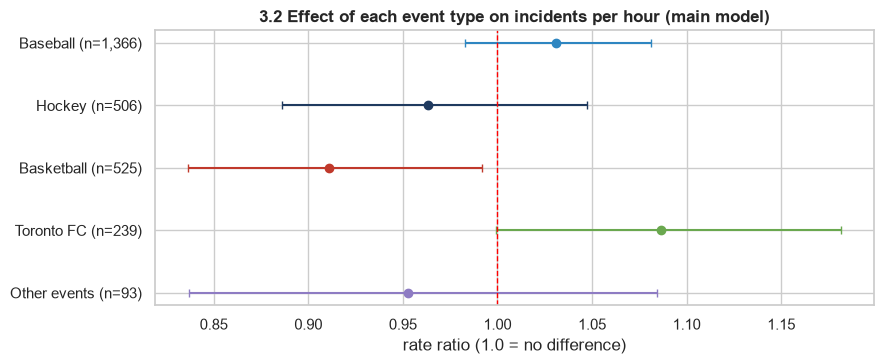

In [23]:
rr = rate_ratios(main)
events_rr = rr.loc[list(EVENT_FLAGS)].rename(index=EVENT_FLAGS)
events_rr["hours"] = [int(model_data[f].sum()) for f in EVENT_FLAGS]

fig, ax = plt.subplots(figsize=(9, 3.8))
y = np.arange(len(events_rr))[::-1]
for yi, (name, row) in zip(y, events_rr.iterrows()):
    ax.errorbar(row["rate_ratio"], yi, xerr=[[row["rate_ratio"] - row["lo"]], [row["hi"] - row["rate_ratio"]]], fmt="o", color=GROUP_COLORS[name], capsize=3)
ax.axvline(1, color="red", ls="--", lw=1)
ax.set_yticks(y)
ax.set_yticklabels([f"{n} (n={h:,})" for n, h in zip(events_rr.index, events_rr["hours"])])
ax.set(title="3.2 Effect of each event type on incidents per hour (main model)", xlabel="rate ratio (1.0 = no difference)")
plt.tight_layout()
events_rr.assign(**{"95% interval": [f"{lo:.2f} to {hi:.2f}" for lo, hi in zip(events_rr["lo"], events_rr["hi"])]})[["hours", "rate_ratio", "95% interval", "p_value"]].round(3)

**How to read it:** each dot is the effect of that event type on incidents per hour, with weekday, hour, month, weather, holiday and coding period held equal. The line is the 95% interval; the red line is "no difference".

**What stands out:**
- **Baseball: 1.03 (0.98 to 1.08).** No difference; the effect is within 3% of zero either way.
- **Hockey: 0.96 (0.89 to 1.05).** No clear difference.
- **Basketball: 0.91 (0.84 to 0.99), p = 0.03.** About 9% fewer incidents than expected, and the interval just stays under 1.
- **Toronto FC: 1.09 (1.00 to 1.18), p = 0.05.** About 9% more, but only just. The interval touches 1.0.
- **Other events: 0.95 (0.84 to 1.08).** No clear difference.

**What it means:** with weather and calendar held equal, **no event type clearly raises incidents**. Basketball is the only one with a clear difference, and it points down. Toronto FC is a borderline rise, and it is the least stable result (see 3.4).

### 3.3 In incidents per hour: what the model expects without the event vs what happened
The model is asked: if these same hours had **no event**, how many incidents would it expect? That is compared with the actual number.

,event hours,expected without event,actual,difference per hour,difference per event (about 8 hours)
Baseball,1366.0,7.57,7.79,0.22,1.79
Hockey,506.0,7.35,7.14,-0.21,-1.71
Basketball,525.0,7.06,6.44,-0.62,-4.92
Toronto FC,239.0,7.25,7.91,0.67,5.33
Other events,93.0,8.34,8.03,-0.31,-2.44


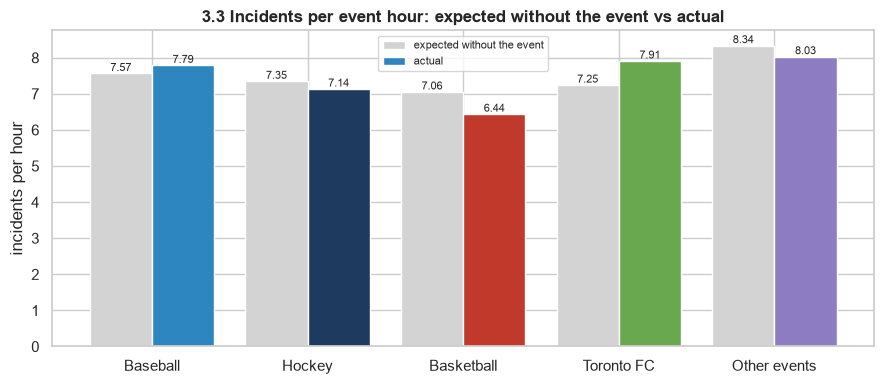

In [24]:
no_event = model_data.copy()
no_event[list(EVENT_FLAGS)] = 0
model_data["fitted"] = main.predict(model_data)
model_data["expected_no_event"] = main.predict(no_event)

rows = {}
for flag, name in EVENT_FLAGS.items():
    sel = model_data[flag] == 1
    rows[name] = {"event hours": int(sel.sum()), "expected without event": model_data.loc[sel, "expected_no_event"].mean(),
                  "actual": model_data.loc[sel, "n_incidents"].mean()}
table = pd.DataFrame(rows).T
table["difference per hour"] = table["actual"] - table["expected without event"]
table["difference per event (about 8 hours)"] = table["difference per hour"] * 8

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(table))
ax.bar(x - 0.2, table["expected without event"], width=0.4, color="lightgray", label="expected without the event")
ax.bar(x + 0.2, table["actual"], width=0.4, color=[GROUP_COLORS[n] for n in table.index], label="actual")
ax.set_xticks(x)
ax.set_xticklabels(table.index)
ax.bar_label(ax.containers[0], fmt="%.2f", fontsize=8)
ax.bar_label(ax.containers[1], fmt="%.2f", fontsize=8)
ax.set(title="3.3 Incidents per event hour: expected without the event vs actual", ylabel="incidents per hour")
ax.legend(fontsize=8)
plt.tight_layout()
table.round(2)

**How to read it:** the grey bar is what the model expects in these hours if there were **no event**, and the coloured bar is what actually happened. Both are incidents per hour across all routes.

**What stands out:**

| Group | Expected | Actual | Difference per hour | Per event (about 8 hours) |
|---|---|---|---|---|
| Baseball | 7.57 | 7.79 | +0.22 | +1.8 |
| Hockey | 7.35 | 7.14 | -0.21 | -1.7 |
| Basketball | 7.06 | 6.44 | -0.62 | -4.9 |
| Toronto FC | 7.25 | 7.91 | +0.67 | +5.3 |
| Other events | 8.34 | 8.03 | -0.31 | -2.4 |

**What it means:** in everyday terms, the biggest difference is about **5 incidents over a whole game** (fewer for basketball, more for Toronto FC), out of roughly 60 expected. For comparison, the whole network has about 170 incidents a day. These are small.

### 3.4 Which controls matter? Adding them one at a time
The event effects are re-estimated as controls are added. If an effect moves a lot, that control was hiding or creating it.

,Baseball,Hockey,Basketball,Toronto FC,Other events
1. events + kind of hour,1.006,0.978,0.901,1.078,0.976
2. + month,1.022,0.980,0.888,1.106,0.945
3. + holiday,1.027,0.982,0.884,1.104,0.947
4. + snow,1.031,0.980,0.903,1.105,0.952
5. + temperature,1.040,0.974,0.910,1.089,0.929
6. + heavy rain,1.037,0.972,0.912,1.094,0.939
"7. + coding period, several events (MAIN)",1.031,0.963,0.911,1.087,0.953


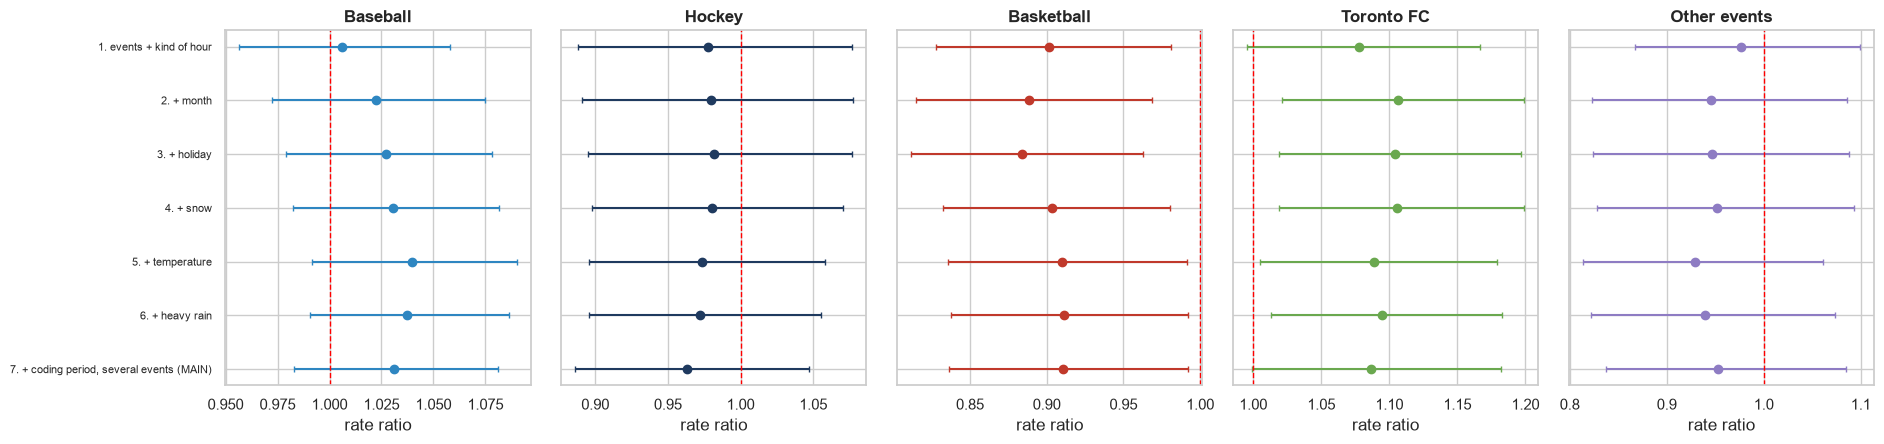

In [25]:
steps = {}
for name, rhs in CONTROL_STEPS.items():
    steps[name] = rate_ratios(fit_poisson(model_data, "n_incidents", rhs)).loc[list(EVENT_FLAGS)].rename(index=EVENT_FLAGS)

fig, axes = plt.subplots(1, 5, figsize=(19, 4.6), sharey=True)
labels = list(CONTROL_STEPS)
ypos = np.arange(len(labels))[::-1]
for ax, group in zip(axes, EVENT_FLAGS.values()):
    for yi, name in zip(ypos, labels):
        row = steps[name].loc[group]
        ax.errorbar(row["rate_ratio"], yi, xerr=[[row["rate_ratio"] - row["lo"]], [row["hi"] - row["rate_ratio"]]], fmt="o", color=GROUP_COLORS[group], capsize=2)
    ax.axvline(1, color="red", ls="--", lw=1)
    ax.set(title=group, xlabel="rate ratio")
axes[0].set_yticks(ypos)
axes[0].set_yticklabels(labels, fontsize=8)
plt.tight_layout()
pd.DataFrame({name: t["rate_ratio"] for name, t in steps.items()}).T.round(3)

**How to read it:** each row adds one more control to the model. If a dot moves a lot between rows, that control matters for that event type.

**What stands out:**
- **The event effects barely move.** Baseball goes from 1.01 to 1.03, hockey from 0.98 to 0.96, and other events from 0.98 to 0.95.
- **Basketball stays at 0.88 to 0.91** at every step. Month and holiday push it to 0.88, and snow lifts it back to 0.90. **Weather and the calendar do not explain the basketball dip.**
- **Toronto FC stays at 1.08 to 1.11**, with the lower end of its interval at or just above 1.0.

**A note on Toronto FC:** in Step 2 the same group was 0.96 when matched on each weekday separately (168 groups) and 1.09 with weekday type only (48 groups). Toronto FC plays almost only on Saturdays, so the way weekends are handled changes its answer. **Treat the Toronto FC result as uncertain.**

**What it means:** the controls matter for the size of the weather and holiday effects (3.5), but not for the event results.

### 3.5 The controls themselves
Do the weather and calendar controls behave as 02_eda said they would?

,rate_ratio,lo,hi,p_value
Public holiday,0.682,0.602,0.772,0.000
Snow that day,1.117,1.038,1.202,0.003
5+ cm snow in last 3 days,1.224,1.107,1.353,0.000
Heavy rain (10+ mm),1.140,1.061,1.225,0.000
After April 2026 (coding change),0.921,0.882,0.961,0.000
Several events that day,1.016,0.954,1.082,0.621
Below -10 C (vs 10 to 20 C),1.170,0.988,1.385,0.068
-10 to 0 C,0.921,0.833,1.020,0.113
0 to 10 C,0.978,0.917,1.043,0.498
20 to 25 C,1.049,0.991,1.111,0.097


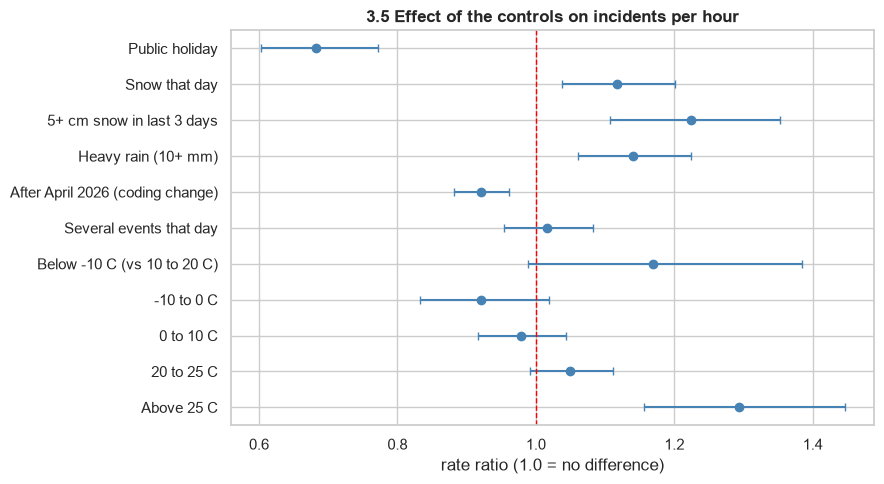

In [26]:
control_names = {
    "is_holiday": "Public holiday", "snow_day": "Snow that day", "snow3_over5": "5+ cm snow in last 3 days", "heavy_rain": "Heavy rain (10+ mm)",
    "after_coding_change": "After April 2026 (coding change)", "multi_event_day": "Several events that day",
    "C(temp_band, Treatment('10 to 20'))[T.below -10]": "Below -10 C (vs 10 to 20 C)",
    "C(temp_band, Treatment('10 to 20'))[T.-10 to 0]": "-10 to 0 C",
    "C(temp_band, Treatment('10 to 20'))[T.0 to 10]": "0 to 10 C",
    "C(temp_band, Treatment('10 to 20'))[T.20 to 25]": "20 to 25 C",
    "C(temp_band, Treatment('10 to 20'))[T.above 25]": "Above 25 C",
}
controls_rr = rr.loc[list(control_names)].rename(index=control_names)
fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(controls_rr))[::-1]
ax.errorbar(controls_rr["rate_ratio"], y, xerr=[controls_rr["rate_ratio"] - controls_rr["lo"], controls_rr["hi"] - controls_rr["rate_ratio"]], fmt="o", color="steelblue", capsize=3)
ax.axvline(1, color="red", ls="--", lw=1)
ax.set_yticks(y)
ax.set_yticklabels(controls_rr.index)
ax.set(title="3.5 Effect of the controls on incidents per hour", xlabel="rate ratio (1.0 = no difference)")
plt.tight_layout()
controls_rr.round(3)

**How to read it:** the effect of each control, with everything else held equal. These are the same kinds of numbers as the event effects, so they show how large an event effect would need to be to matter.

**What stands out:** they all behave as Step 6 of 02_eda predicted.
- **Public holiday: 0.68** (32% fewer incidents).
- **Snow that day: 1.12** (12% more), and **5+ cm in the last 3 days: 1.22** (22% more).
- **Heavy rain: 1.14** (14% more).
- **Above 25 C: 1.29** (29% more than on a 10 to 20 C day). **Below -10 C: 1.17**, with a wide interval (0.99 to 1.39).
- **After April 2026: 0.92** (8% fewer), matching the lower level in 2026.
- **Several events that day: 1.02** (no difference), so double-event days are not special.

**What it means:** every event effect in 3.2 (3% to 9%) is **smaller than a snow day, a hot day or a holiday**. Event hours are not a major driver of incidents.

### 3.6 Does the model fit? Actual vs fitted by hour of the day

Average gap actual - fitted: 0.0000 | correlation between actual and fitted: 0.58


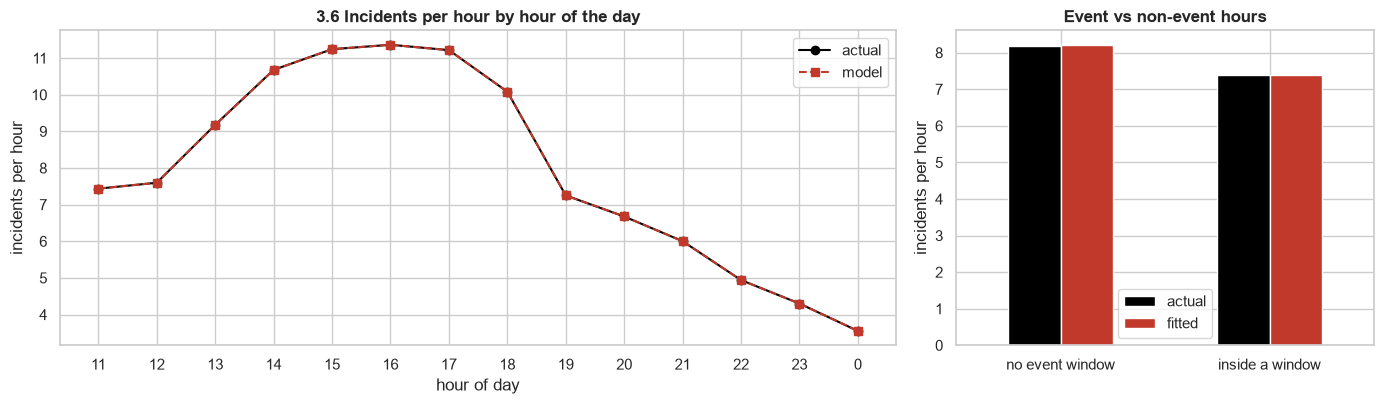

In [27]:
fit_check = model_data.groupby("hour").agg(actual=("n_incidents", "mean"), fitted=("fitted", "mean"))
fit_check = fit_check.reindex(list(range(11, 24)) + [0])
event_fit = model_data.groupby("in_event_window").agg(actual=("n_incidents", "mean"), fitted=("fitted", "mean"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [2, 1]})
axes[0].plot(range(len(fit_check)), fit_check["actual"], marker="o", label="actual", color="black")
axes[0].plot(range(len(fit_check)), fit_check["fitted"], marker="s", ls="--", label="model", color="#c0392b")
axes[0].set_xticks(range(len(fit_check)))
axes[0].set_xticklabels(fit_check.index)
axes[0].set(title="3.6 Incidents per hour by hour of the day", xlabel="hour of day", ylabel="incidents per hour")
axes[0].legend()
event_fit.index = ["no event window", "inside a window"]
event_fit.plot.bar(ax=axes[1], color=["black", "#c0392b"], rot=0)
axes[1].set(title="Event vs non-event hours", ylabel="incidents per hour")
plt.tight_layout()
resid = (model_data["n_incidents"] - model_data["fitted"])
print(f"Average gap actual - fitted: {resid.mean():.4f} | correlation between actual and fitted: {model_data['n_incidents'].corr(model_data['fitted']):.2f}")

**How to read it:** the left chart compares the real average incidents per hour with what the model fits, for each hour of the day. The right chart compares event hours and non-event hours.

**An honest note:** the lines sit exactly on top of each other, and the average gap is 0, **because the model has a separate group for each weekday type and hour**. That is built in, not an independent test.

**What is a real sign of fit:** the correlation between actual and fitted counts is 0.58. That is moderate, which is expected, since a single hour has a lot of random variation (the variation is 2 times a plain Poisson). The model captures the pattern, not each hour's luck.

### Step 3 takeaways
- **No type of event clearly raises incidents.** With weekday, hour, month, weather, holiday and coding period held equal: baseball **1.03**, hockey **0.96**, other events **0.95** (all within chance), basketball **0.91**, Toronto FC **1.09**.
- **Basketball is lower by about 9%** (0.84 to 0.99), roughly 0.6 fewer incidents an hour or 5 over a game. It is stable in every version, so it is not a weather or calendar effect.
- **Toronto FC is borderline higher (1.09, p = 0.05)** and **unstable**: it was 0.96 in Step 2 with a different weekday grouping. We should not read it as an effect yet.
- **Controls change the event effects by at most about 0.03.** They matter for the weather and calendar effects themselves, which behave as expected: holiday 0.68, snow 1.12 and 1.22, heavy rain 1.14, hot days 1.29.
- **Size check:** every event effect (3% to 9%) is smaller than a snow day, a hot day or a holiday.
- **Limits:** with five event groups and several outcomes, borderline p-values (0.03, 0.05) should not be over-read. The model cannot prove cause.

**Next:** the same model for **diversions, delay minutes and long delays**, then **hours around the start**, **near-venue vs other routes** (the test for the city-event lead from Step 2), and **cause groups**.

## Step 4. The near-venue test

**The question.** Do events add **more** incidents on the routes that run near a venue than on the rest of the network?

**How the data is arranged.** Each hour gets **two rows**: one with the incidents on the 21 routes within 1 km of a venue, and one with the incidents on all other routes
(17,864 rows). A `near` indicator marks the near-venue row.

**The recipe.**

> incidents on a route group in an hour = **a usual level for that group** (its own pattern by hour type and month)
> × **weather and calendar adjustment** (the same for both groups)
> × **event effect on other routes**
> × **extra event effect near the venue** (the number being tested)

**How to read the answer**

| Quantity | Meaning |
|---|---|
| **Other routes** | The event effect on the rest of the network (rate ratio). |
| **Extra near-venue effect** | The near-venue ratio divided by the other-routes ratio. **1.00 = the effect is the same near the venue as elsewhere**; above 1 = bigger near the venue. |
| **Near-venue routes** | The event effect on the near-venue routes themselves. |

Events are grouped into two flags (sports and other city events) so that the near-venue routes, which have only about 0.6 incidents an hour, have enough data. Intervals are computed by evening, as in Step 3.

### 4.0 Set up the two-row data

In [28]:
route_dist = pd.read_csv(PROCESSED / "route_venue_dist.csv")
model_data["win_sports"] = (model_data[["win_mlb", "win_nhl", "win_nba", "win_mls"]].sum(axis=1) > 0).astype(int)
CONTROLS = ("is_holiday + snow_day + snow3_over5 + C(temp_band, Treatment('10 to 20')) + heavy_rain + after_coding_change + multi_event_day")


def hourly_count(mask):
    """Incidents per hour for the incidents selected by `mask`, aligned with model_data."""
    counts = incidents.loc[mask].groupby(incidents["datetime"].dt.floor("h")).size()
    return counts.reindex(model_data["datetime"], fill_value=0).to_numpy()


def stack(near_counts, other_counts, data=None):
    """Two rows per hour: near-venue routes and the other routes."""
    data = model_data if data is None else data
    return pd.concat([data.assign(grp="near", count=near_counts, near=1), data.assign(grp="other", count=other_counts, near=0)], ignore_index=True)


def fit_near(st, flags, controls=CONTROLS):
    """Poisson: each group has its own usual level (slot, month); flags and flags x near are the event effects."""
    terms = " + ".join(flags) + " + " + " + ".join(f"{f}:near" for f in flags)
    model = smf.glm(f"count ~ {terms} + C(grp):C(slot) + C(grp):C(month) + {controls}", data=st, family=sm.families.Poisson())
    return model.fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(st["evening_date"])[0]})


def near_effects(res, flags, names=None):
    """For each flag: effect on other routes, extra near-venue effect, and effect on near-venue routes (rate ratios with 95% intervals)."""
    names = names or {f: f for f in flags}
    params, cov = res.params, res.cov_params()
    rows = []
    for f in flags:
        for label, members in [("Other routes", [f]), ("Extra near-venue effect", [f"{f}:near"]), ("Near-venue routes", [f, f"{f}:near"])]:
            L = pd.Series(0.0, index=params.index)
            L[members] = 1.0
            est = float(L @ params)
            se = float(np.sqrt(L @ cov @ L))
            rows.append({"event": names[f], "quantity": label, "rate_ratio": np.exp(est), "lo": np.exp(est - 1.96 * se), "hi": np.exp(est + 1.96 * se)})
    return pd.DataFrame(rows)


near_main = stack(model_data["n_near_venue"].to_numpy(), model_data["n_other_routes"].to_numpy())
print(f"{len(near_main):,} rows | near-venue incidents: {int(model_data['n_near_venue'].sum()):,} "
      f"({int(model_data.loc[model_data['in_event_window'] == 1, 'n_near_venue'].sum()):,} in event hours)")

17,864 rows | near-venue incidents: 5,908 (1,637 in event hours)


**What this shows:** the two-row data has 17,864 rows. Routes near a venue had **5,908 incidents** in the period, **1,637 of them in event hours**.

### 4.1 The raw numbers first
Incidents per hour near the venue and elsewhere, inside and outside event windows. No model yet.

,n hours,near-venue routes,other routes,share near venue (%)
hours,,,,
no event window,6413,0.67,7.24,8.43
sports window,2467,0.64,6.43,9.10
city-event window,93,0.91,6.92,11.66


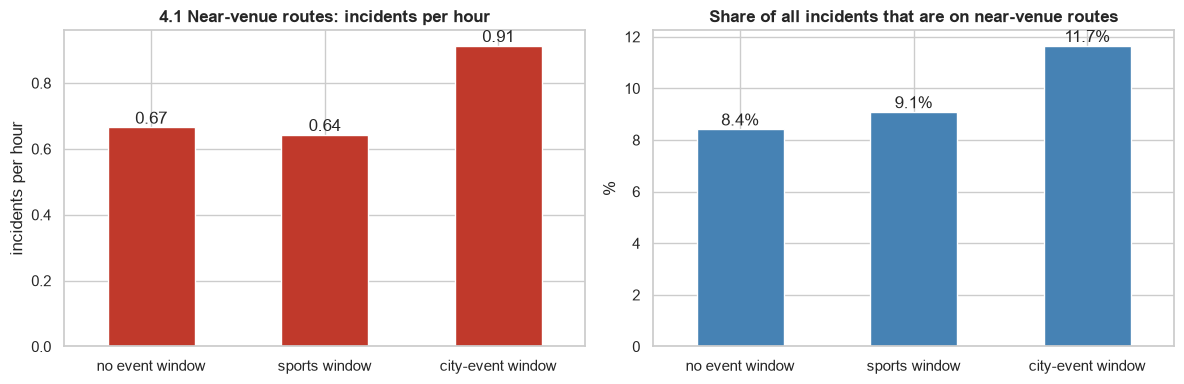

In [29]:
raw = []
for name, mask in [("no event window", model_data["in_event_window"] == 0), ("sports window", model_data["win_sports"] == 1), ("city-event window", model_data["win_other"] == 1)]:
    sub = model_data[mask]
    raw.append({"hours": name, "n hours": len(sub), "near-venue routes": sub["n_near_venue"].mean(), "other routes": sub["n_other_routes"].mean(),
                "share near venue (%)": sub["n_near_venue"].sum() / (sub["n_near_venue"].sum() + sub["n_other_routes"].sum()) * 100})
raw = pd.DataFrame(raw).set_index("hours")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
raw[["near-venue routes"]].plot.bar(ax=axes[0], color="#c0392b", rot=0, legend=False)
axes[0].bar_label(axes[0].containers[0], fmt="%.2f")
axes[0].set(title="4.1 Near-venue routes: incidents per hour", xlabel="", ylabel="incidents per hour")
raw[["share near venue (%)"]].plot.bar(ax=axes[1], color="steelblue", rot=0, legend=False)
axes[1].bar_label(axes[1].containers[0], fmt="%.1f%%")
axes[1].set(title="Share of all incidents that are on near-venue routes", xlabel="", ylabel="%")
plt.tight_layout()
raw.round(2)

**How to read it:** the average incidents per hour on near-venue routes, and the share of all incidents that happen on them, in hours with no event, with a sports window and with a city-event window. No model, no controls.

**What stands out:**
- Near-venue routes have **0.67 incidents an hour with no event, 0.64 in sports hours and 0.91 in city-event hours**.
- Their share of all incidents is **8.4% with no event, 9.1% in sports hours and 11.7% in city-event hours**.

**What it means:** in the raw numbers sports hours look like normal hours, while the city-event hours are higher near the venue. The raw numbers do not hold weekday, time or weather equal, so the model is next.

### 4.2 Main result: sports and other city events

quantity,Other routes,Extra near-venue effect,Near-venue routes
event,,,
"Other city events (parades, festivals, World Cup)",0.93 (0.82 to 1.06),1.31 (1.15 to 1.48),1.22 (1.04 to 1.42)
"Sports (baseball, hockey, basketball, Toronto FC)",0.99 (0.95 to 1.04),1.01 (0.94 to 1.09),1.01 (0.93 to 1.09)


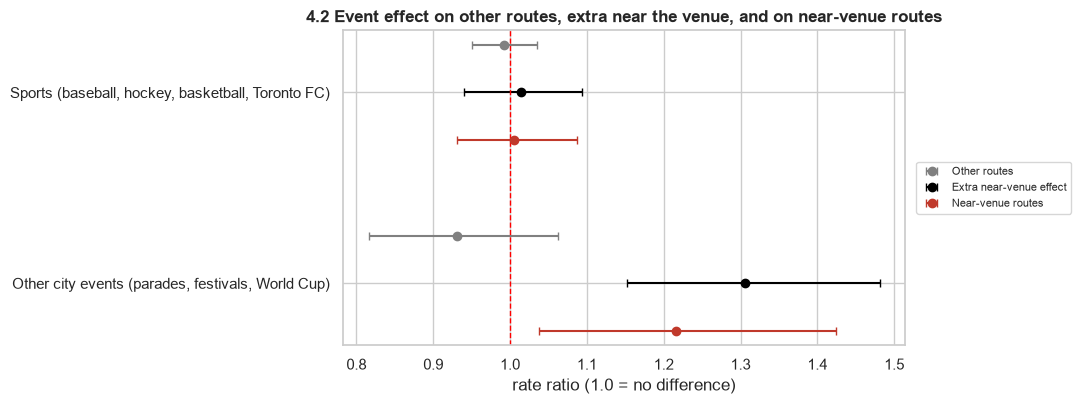

In [30]:
FLAGS_MAIN = ["win_sports", "win_other"]
NAMES_MAIN = {"win_sports": "Sports (baseball, hockey, basketball, Toronto FC)", "win_other": "Other city events (parades, festivals, World Cup)"}
res_main = fit_near(near_main, FLAGS_MAIN)
effects_main = near_effects(res_main, FLAGS_MAIN, NAMES_MAIN)
QUANTITY_COLORS = {"Other routes": "gray", "Extra near-venue effect": "black", "Near-venue routes": "#c0392b"}


def plot_effects(effects, title, figsize=(11, 4.2)):
    events_list = list(dict.fromkeys(effects["event"]))
    fig, ax = plt.subplots(figsize=figsize)
    for i, ev_name in enumerate(events_list[::-1]):
        for j, q in enumerate(QUANTITY_COLORS):
            row = effects[(effects["event"] == ev_name) & (effects["quantity"] == q)].iloc[0]
            y = i + (1 - j) * 0.25
            ax.errorbar(row["rate_ratio"], y, xerr=[[row["rate_ratio"] - row["lo"]], [row["hi"] - row["rate_ratio"]]], fmt="o", color=QUANTITY_COLORS[q], capsize=3,
                        label=q if i == 0 else None)
    ax.axvline(1, color="red", ls="--", lw=1)
    ax.set_yticks(range(len(events_list)))
    ax.set_yticklabels(events_list[::-1])
    ax.set(title=title, xlabel="rate ratio (1.0 = no difference)")
    ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
    plt.tight_layout()


def effects_table(effects):
    t = effects.assign(**{"ratio (95% interval)": [f"{r:.2f} ({lo:.2f} to {hi:.2f})" for r, lo, hi in zip(effects["rate_ratio"], effects["lo"], effects["hi"])]})
    return t.pivot(index="event", columns="quantity", values="ratio (95% interval)")[list(QUANTITY_COLORS)]


plot_effects(effects_main, "4.2 Event effect on other routes, extra near the venue, and on near-venue routes")
effects_table(effects_main)

**How to read it:** for each kind of event, three dots. **Grey** is the effect on all other routes. **Black** is the **extra** effect near the venue (the number being tested; 1.0 means no extra). **Red** is the effect on the near-venue routes themselves. The table gives the same numbers with their 95% intervals.

**What stands out:**
- **Sports:** other routes **0.99**, extra near-venue effect **1.01 (0.94 to 1.09)**, near-venue routes **1.01 (0.93 to 1.09)**. **Sports hours change nothing near the venue.**
- **Other city events:** other routes 0.93 (0.82 to 1.06), but the **extra near-venue effect is 1.31 (1.15 to 1.48)** and the effect on near-venue routes is **1.22 (1.04 to 1.42)**. **About 22% more incidents on the routes near the venue**, and the effect there is about 31% larger than on the rest of the network.

**Caution:** these intervals come from the model and are **too narrow** for the city events: there are only 12 events (93 hours). The fake-event check in 4.7 shows how wide the real uncertainty is.

### 4.3 One effect per event type

quantity,Other routes,Extra near-venue effect,Near-venue routes
event,,,
Baseball,1.02 (0.97 to 1.07),1.03 (0.94 to 1.12),1.05 (0.96 to 1.15)
Basketball,0.91 (0.84 to 1.00),0.96 (0.83 to 1.11),0.87 (0.75 to 1.02)
Hockey,0.96 (0.88 to 1.05),0.98 (0.86 to 1.13),0.95 (0.82 to 1.10)
Other events,0.94 (0.82 to 1.07),1.31 (1.15 to 1.49),1.23 (1.05 to 1.44)
Toronto FC,1.09 (0.99 to 1.19),1.11 (0.92 to 1.33),1.20 (1.01 to 1.43)


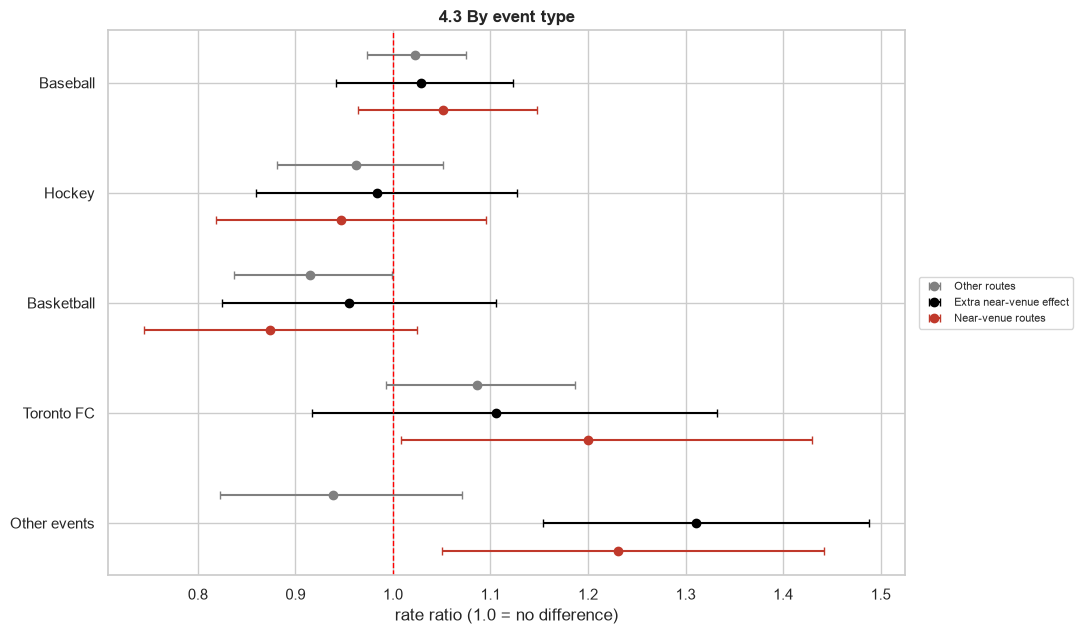

In [31]:
FLAGS_TYPE = list(EVENT_FLAGS)
res_type = fit_near(near_main, FLAGS_TYPE)
effects_type = near_effects(res_type, FLAGS_TYPE, EVENT_FLAGS)
plot_effects(effects_type, "4.3 By event type", figsize=(11, 6.5))
effects_table(effects_type)

**How to read it:** the same three dots for each of the five event types.

**What stands out:**
- **Baseball, hockey and basketball:** nothing near the venue. The near-venue ratios are 1.05 (0.96 to 1.15), 0.95 (0.82 to 1.10) and 0.87 (0.75 to 1.02). Basketball is lower near the venue too, but not clearly.
- **Toronto FC:** near-venue **1.20 (1.01 to 1.43)** with an extra effect of 1.11 (0.92 to 1.33). A hint of a rise, but it only just clears 1.0, and Toronto FC was unstable in Steps 2 and 3.
- **Other city events:** 1.23 near the venue and 1.31 extra, the same as the pooled result.

**What it means:** the pooled "other events" lead is not coming from the sports, and no sport shows a clear near-venue effect.

### 4.4 Splitting the city events
Parades, the World Cup and festivals together are only 93 hours. Split, each group is tiny, so treat this as a look at **where the rise comes from**, not as an estimate.

Event hours in scope: {'win_parade': 43, 'win_world_cup': 42, 'win_festival': 8}


quantity,Other routes,Extra near-venue effect,Near-venue routes,hours
event,,,,
Festivals (Nuit Blanche),1.06 (0.94 to 1.20),1.44 (1.23 to 1.69),1.53 (1.26 to 1.85),8
Parades,0.89 (0.72 to 1.10),1.24 (1.08 to 1.43),1.10 (0.93 to 1.31),43
World Cup,0.97 (0.81 to 1.16),1.37 (1.12 to 1.68),1.33 (1.02 to 1.73),42


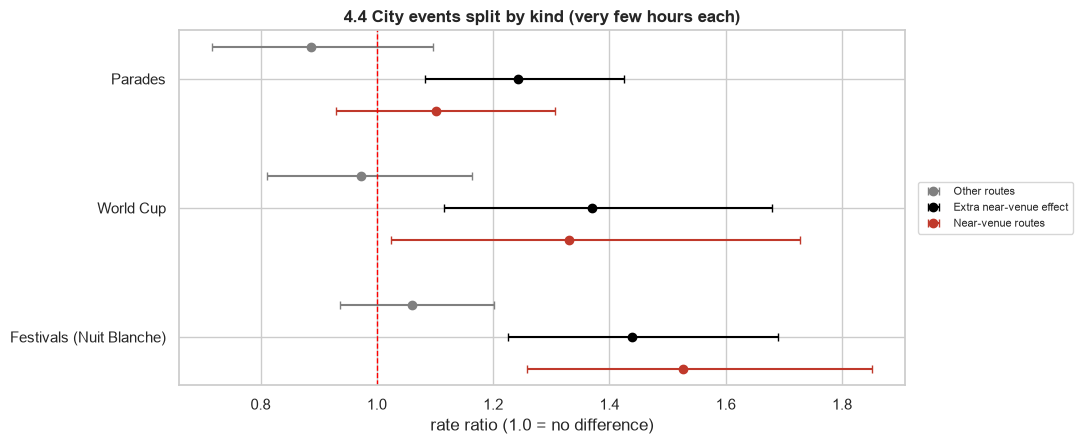

In [32]:
type_of_event = timed.set_index("event_id")["event_type"]
sub_flags = (pd.crosstab(window_rows["datetime"], window_rows["event_id"].map(type_of_event)).gt(0).astype(int)
             .reindex(columns=["parade", "world_cup", "festival"], fill_value=0).add_prefix("win_").reset_index())
split_data = model_data.drop(columns=[c for c in model_data.columns if c in ["win_parade", "win_world_cup", "win_festival"]]).merge(sub_flags, on="datetime", how="left")
for col in ["win_parade", "win_world_cup", "win_festival"]:
    split_data[col] = split_data[col].fillna(0).astype(int)
hours_by_sub = {c: int(split_data[c].sum()) for c in ["win_parade", "win_world_cup", "win_festival"]}
print("Event hours in scope:", hours_by_sub)

near_split = stack(split_data["n_near_venue"].to_numpy(), split_data["n_other_routes"].to_numpy(), data=split_data)
flags_split = ["win_mlb", "win_nhl", "win_nba", "win_mls", "win_parade", "win_world_cup", "win_festival"]
res_split = fit_near(near_split, flags_split)
names_split = {**EVENT_FLAGS, "win_parade": "Parades", "win_world_cup": "World Cup", "win_festival": "Festivals (Nuit Blanche)"}
effects_split = near_effects(res_split, ["win_parade", "win_world_cup", "win_festival"], names_split)
plot_effects(effects_split, "4.4 City events split by kind (very few hours each)", figsize=(11, 4.6))
effects_table(effects_split).assign(hours=[hours_by_sub[k] for k in ["win_festival", "win_parade", "win_world_cup"]])

**How to read it:** the city events split into parades (43 hours in scope), the World Cup (42 hours) and festivals (8 hours, only Nuit Blanche). Each is tiny, so this shows where the rise comes from, not how big each is.

**What stands out:** **all three point the same way**:
- **World Cup:** extra near-venue effect 1.37 (1.12 to 1.68), near-venue routes **1.33 (1.02 to 1.73)**.
- **Parades:** extra effect 1.24 (1.08 to 1.43), near-venue routes 1.10 (0.93 to 1.31).
- **Festivals (Nuit Blanche, 8 hours):** 1.44 and 1.53. Eight hours is too few to rely on.

**What it means:** the rise is not just one kind of event. But each kind rests on one to six events, so this is a pattern to note, not a result.

### 4.5 Before, during and after the start (sports)
Sports hours are split by distance from the start: **before** (2 and 1 hours before), **during** (the first 3 hours, until the assumed end) and **after** (the last hours of the window).

quantity,Other routes,Extra near-venue effect,Near-venue routes,hours
event,,,,
Sports: after the end,1.00 (0.93 to 1.07),1.00 (0.87 to 1.14),1.00 (0.87 to 1.14),846
Sports: before the start,0.99 (0.93 to 1.05),1.01 (0.90 to 1.14),1.00 (0.89 to 1.12),660
Sports: during the game,0.99 (0.94 to 1.04),1.03 (0.93 to 1.14),1.02 (0.92 to 1.13),961


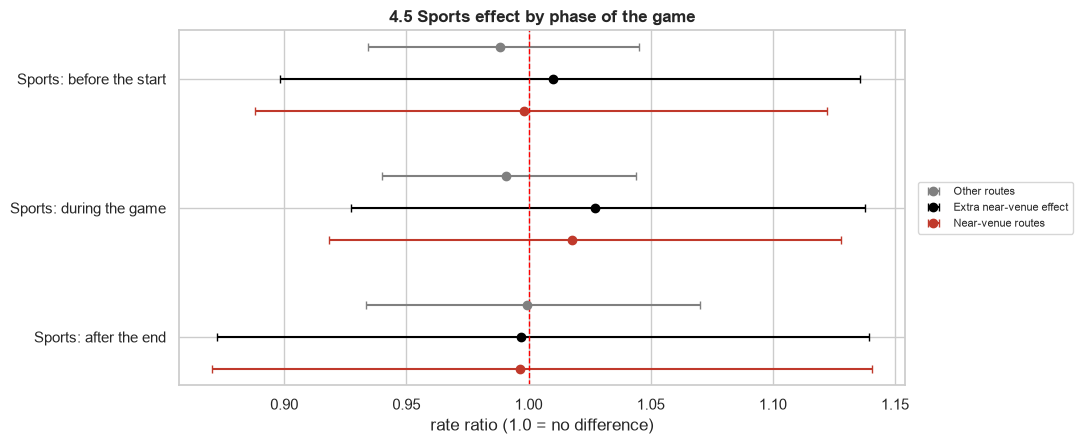

In [33]:
sport_rows = ev_hours[ev_hours["group"].isin(["mlb", "nhl", "nba", "mls"])]
first_offset = sport_rows.groupby("datetime")["offset"].min()
phase = pd.cut(first_offset, [-10, -1, 2, 10], labels=["before", "during", "after"]).rename("phase")
phase_flags = pd.get_dummies(phase).astype(int).add_prefix("win_s_").reset_index()
phase_data = model_data.drop(columns=[c for c in model_data.columns if c.startswith("win_s_")]).merge(phase_flags, on="datetime", how="left")
phase_cols = ["win_s_before", "win_s_during", "win_s_after"]
phase_data[phase_cols] = phase_data[phase_cols].fillna(0).astype(int)
phase_data["win_other_only"] = phase_data["win_other"]
near_phase = stack(phase_data["n_near_venue"].to_numpy(), phase_data["n_other_routes"].to_numpy(), data=phase_data)
res_phase = fit_near(near_phase, phase_cols + ["win_other_only"])
names_phase = {"win_s_before": "Sports: before the start", "win_s_during": "Sports: during the game", "win_s_after": "Sports: after the end"}
effects_phase = near_effects(res_phase, phase_cols, names_phase)
plot_effects(effects_phase, "4.5 Sports effect by phase of the game", figsize=(11, 4.6))
effects_table(effects_phase).assign(hours=[int(phase_data[c].sum()) for c in ["win_s_after", "win_s_before", "win_s_during"]])

**How to read it:** sports hours split into before the start (2 and 1 hours before), during the game (the first 3 hours) and after the end (the rest of the window). Same three dots per phase.

**What stands out:** **all three phases are flat**: near-venue routes are 1.00 before, 1.02 during and 1.00 after, and the extra effect is 1.01, 1.03 and 1.00. **There is no sign of extra trouble near the venue when fans arrive, during the game or when they leave.**

**What it means:** the sports result (no near-venue effect) does not hide a short peak. The 1 km routes are not affected at any point of the game.

### 4.6 Does the definition of "near" change the answer?
Four checks, each on the extra near-venue effect:
**3 km** instead of 1 km (33 routes), **without night routes (3xx)**, a **venue-specific** version (a route counts as near only if it is near the venue of that event: baseball at Rogers Centre,
hockey and basketball at Scotiabank Arena, Toronto FC at BMO Field), and the **main** definition for reference.

quantity                                                                     Extra near-venue effect    Near-venue routes
event                                             definition                                                             
Baseball                                          venue-specific                 1.21 (0.98 to 1.50)  1.24 (1.00 to 1.54)
Basketball                                        venue-specific                 1.02 (0.82 to 1.29)  0.93 (0.73 to 1.19)
Hockey                                            venue-specific                 0.94 (0.75 to 1.18)  0.90 (0.73 to 1.12)
Other city events (parades, festivals, World Cup) 1 km, without night routes     1.31 (1.15 to 1.48)  1.22 (1.04 to 1.42)
                                                  3 km                           1.18 (1.04 to 1.35)  1.10 (0.92 to 1.31)
                                                  main: 1 km                     1.31 (1.15 to 1.48)  1.22 (1.04 to 1.42)
Sports (baseball, hockey, basketball, Toronto FC) 1 km, without night routes     1.01 (0.94 to 1.09)  1.01 (0.93 to 1.09)
                                                  3 km                           1.00 (0.94 to 1.07)  1.00 (0.93 to 1.07)
                                                  main: 1 km                     1.01 (0.94 to 1.09)  1.01 (0.93 to 1.09)
Toronto FC                                        venue-specific                 1.24 (1.00 to 1.53)  1.33 (1.08 to 1.65)

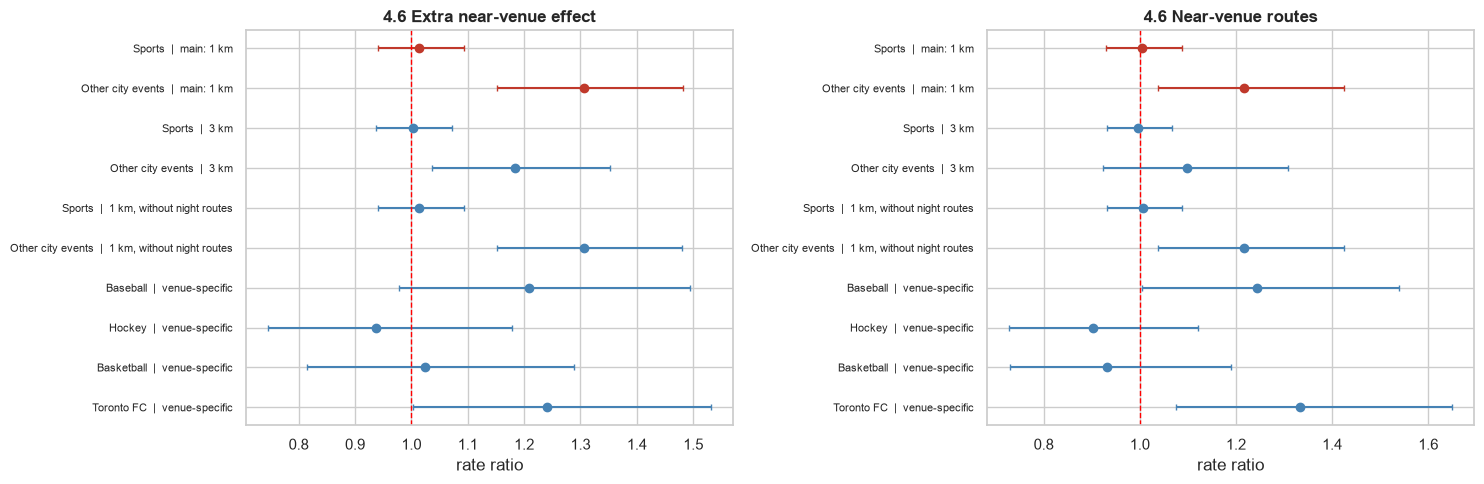

In [34]:
route = incidents["route"]
night = route.between(300, 399)
near1 = incidents["near_venue"].eq(True)
other1 = incidents["near_venue"].eq(False)
near3_routes = set(route_dist.loc[route_dist["dist_venue_km"] <= 3, "route"])
near3 = route.isin(near3_routes)
other3 = route.notna() & ~near3

definitions = {
    "main: 1 km": (hourly_count(near1), hourly_count(other1)),
    "3 km": (hourly_count(near3), hourly_count(other3)),
    "1 km, without night routes": (hourly_count(near1 & ~night), hourly_count(other1 & ~night)),
}
sens_rows = []
for name, (n_counts, o_counts) in definitions.items():
    res = fit_near(stack(n_counts, o_counts), FLAGS_MAIN)
    eff = near_effects(res, FLAGS_MAIN, NAMES_MAIN)
    for _, row in eff[eff["quantity"] != "Other routes"].iterrows():
        sens_rows.append({"definition": name, **row.to_dict()})

# venue-specific: one model per sport, with near = within 1 km of that sport's venue
venue_col = {"win_mlb": "dist_rogers_km", "win_nhl": "dist_scotiabank_km", "win_nba": "dist_scotiabank_km", "win_mls": "dist_bmo_km"}
for flag, col in venue_col.items():
    venue_near = set(route_dist.loc[route_dist[col] <= 1, "route"])
    near_v = route.isin(venue_near)
    other_v = route.notna() & ~near_v
    res = fit_near(stack(hourly_count(near_v), hourly_count(other_v)), list(EVENT_FLAGS))
    eff = near_effects(res, [flag], EVENT_FLAGS)
    for _, row in eff[eff["quantity"] != "Other routes"].iterrows():
        sens_rows.append({"definition": "venue-specific", **row.to_dict()})
sens = pd.DataFrame(sens_rows)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=False)
for ax, quantity in zip(axes, ["Extra near-venue effect", "Near-venue routes"]):
    sub = sens[sens["quantity"] == quantity].reset_index(drop=True)
    sub["label"] = sub["event"].str.replace(r" \(.*\)", "", regex=True) + "  |  " + sub["definition"]
    y = np.arange(len(sub))[::-1]
    colors = ["#c0392b" if d == "main: 1 km" else "steelblue" for d in sub["definition"]]
    for yi, (_, row), color in zip(y, sub.iterrows(), colors):
        ax.errorbar(row["rate_ratio"], yi, xerr=[[row["rate_ratio"] - row["lo"]], [row["hi"] - row["rate_ratio"]]], fmt="o", color=color, capsize=2)
    ax.axvline(1, color="red", ls="--", lw=1)
    ax.set_yticks(y)
    ax.set_yticklabels(sub["label"], fontsize=8)
    ax.set(title=f"4.6 {quantity}", xlabel="rate ratio")
plt.tight_layout()
sens.assign(**{"ratio (95% interval)": [f"{r:.2f} ({lo:.2f} to {hi:.2f})" for r, lo, hi in zip(sens["rate_ratio"], sens["lo"], sens["hi"])]}).pivot_table(
    index=["event", "definition"], columns="quantity", values="ratio (95% interval)", aggfunc="first")

**How to read it:** the extra near-venue effect (left) and the effect on near-venue routes (right) under different definitions of "near". The red dots are the main definition.

**What stands out:**
- **Without night routes, nothing changes** (city events 1.31 and 1.22; sports 1.01).
- **With 3 km instead of 1 km, the city-event effect gets smaller**: extra 1.18 (1.04 to 1.35) and near-venue 1.10 (0.92 to 1.31). Sports stay at 1.00. A weaker result when more routes are included is what we would expect if the effect is close to the venue.
- **Venue-specific "near"** (a route is near only if it is near the venue of that event): **baseball 1.24 (1.00 to 1.54)** and **Toronto FC 1.33 (1.08 to 1.65)** on near-venue routes, hockey 0.90 and basketball 0.93. Baseball and Toronto FC lean up with this stricter definition.

**What it means:** the city-event result survives dropping night routes and gets weaker with a wider definition. The venue-specific numbers hint that a stricter definition may find small increases for baseball and Toronto FC. These are borderline, based on fewer routes, and have the same problem with narrow intervals. They are leads to check, not results.

### 4.7 What does chance look like? Fake city events
The city-event result rests on 93 hours from 12 events. To see how far chance alone can go, the 12 city events are moved to **random days with no event and the same weekday** (same hours), the model is refitted, and the near-venue results are collected.
Repeated 200 times. The red line is the real result.

200 refits in 92 s | fake events: extra near-venue effect mean 1.01, 2.5% to 97.5%: 0.74 to 1.33; share as high as the real one: 0.045
Near-venue routes effect: fake mean 1.03, 2.5% to 97.5%: 0.74 to 1.35; share as high as the real one: 0.140
Spread of the extra effect: model standard error 0.064 vs fake-event spread 0.162 (on the log scale)


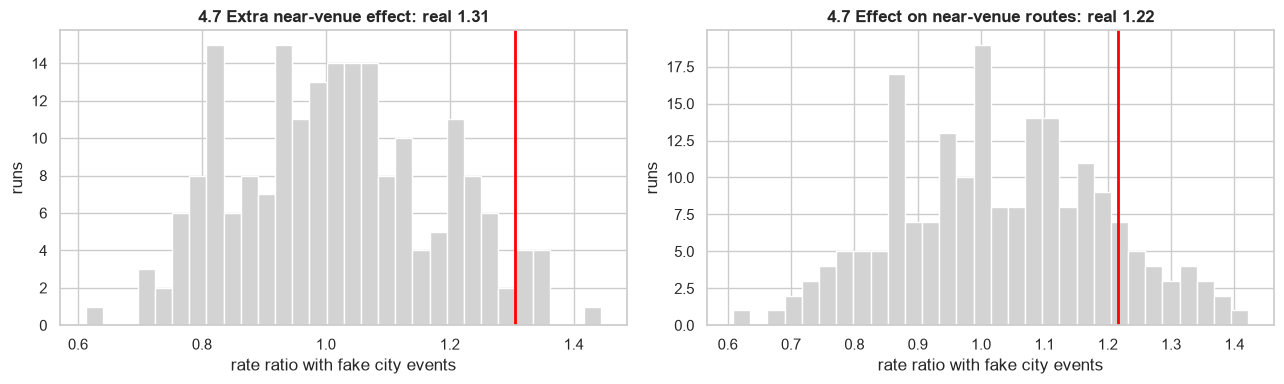

In [35]:
import time

other_ev = ev[ev["group"] == "other"].copy()
other_windows = windows[windows["group"] == "other"].reset_index(drop=True)
other_win_index = other_windows.reset_index().set_index("event_id")["index"]
o_win = other_ev["event_id"].map(other_win_index).to_numpy()
o_off = other_ev["offset_h"].to_numpy().astype("timedelta64[h]")
o_wd = other_windows["weekday"].to_numpy()
mh_pos = pd.DatetimeIndex(model_data["datetime"])
real_window = model_data["in_event_window"].to_numpy().astype(bool)


def fake_city_effect(rng):
    pick = (rng.random(len(other_windows)) * cand_len[o_wd]).astype(int)
    target = cand[o_wd, pick][o_win] + o_off
    pos = mh_pos.get_indexer(pd.DatetimeIndex(target))
    pos = pos[(pos >= 0)]
    pos = pos[~real_window[pos]]
    data = model_data.copy()
    data["win_other"] = 0
    data.loc[data.index[pos], "win_other"] = 1
    res = fit_near(stack(data["n_near_venue"].to_numpy(), data["n_other_routes"].to_numpy(), data=data), FLAGS_MAIN)
    eff = near_effects(res, ["win_other"]).set_index("quantity")["rate_ratio"]
    return eff["Extra near-venue effect"], eff["Near-venue routes"]


rng = np.random.default_rng(7)
start = time.time()
fake_runs = np.array([fake_city_effect(rng) for _ in range(200)])
real_extra = effects_main[(effects_main["event"] == NAMES_MAIN["win_other"]) & (effects_main["quantity"] == "Extra near-venue effect")]["rate_ratio"].iloc[0]
real_near = effects_main[(effects_main["event"] == NAMES_MAIN["win_other"]) & (effects_main["quantity"] == "Near-venue routes")]["rate_ratio"].iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, values, real_value, title in zip(axes, fake_runs.T, [real_extra, real_near], ["Extra near-venue effect", "Effect on near-venue routes"]):
    ax.hist(values, bins=30, color="lightgray")
    ax.axvline(real_value, color="red", lw=2)
    ax.set(title=f"4.7 {title}: real {real_value:.2f}", xlabel="rate ratio with fake city events", ylabel="runs")
plt.tight_layout()
print(f"200 refits in {time.time() - start:.0f} s | fake events: extra near-venue effect mean {fake_runs[:, 0].mean():.2f}, 2.5% to 97.5%: "
      f"{np.percentile(fake_runs[:, 0], 2.5):.2f} to {np.percentile(fake_runs[:, 0], 97.5):.2f}; share as high as the real one: {(fake_runs[:, 0] >= real_extra).mean():.3f}")
print(f"Near-venue routes effect: fake mean {fake_runs[:, 1].mean():.2f}, 2.5% to 97.5%: {np.percentile(fake_runs[:, 1], 2.5):.2f} to {np.percentile(fake_runs[:, 1], 97.5):.2f}; "
      f"share as high as the real one: {(fake_runs[:, 1] >= real_near).mean():.3f}")
model_se = (np.log(effects_main.query("quantity == 'Extra near-venue effect' and event == @NAMES_MAIN['win_other']")["hi"].iloc[0]) - np.log(real_extra)) / 1.96
print(f"Spread of the extra effect: model standard error {model_se:.3f} vs fake-event spread {np.log(fake_runs[:, 0]).std():.3f} (on the log scale)")

**How to read it:** the 12 city events were moved to random days without events (same weekday, same hours) and the model refitted 200 times. The grey histograms show the results that fake events give. The red line is the real result.

**What stands out:**
- **Extra near-venue effect (left):** the fake events give a mean of 1.01 and a range of **0.74 to 1.33**. The real 1.31 is at the top end: **4.5% of the fake runs are as high**.
- **Effect on near-venue routes (right):** the fake range is 0.74 to 1.35. The real **1.22 is not unusual: 14% of the fake runs are as high**.
- **The model's interval is far too narrow.** The model's standard error for the extra effect is 0.064, but the spread across fake events is 0.162, about **2.5 times larger**. A realistic interval for the extra near-venue effect is about **0.95 to 1.8**, not 1.15 to 1.48.

**What it means:** the city-event result is **suggestive but not solid**. The extra effect near the venue is high compared with chance (about 1 in 22), but the direct effect on near-venue routes is within what chance gives. With 12 events, we cannot be sure.

### Step 4 takeaways
- **Sports: no near-venue effect.** Near-venue routes are at **1.01 (0.93 to 1.09)** with an extra effect of 1.01. Flat before, during and after the game (1.00 to 1.02). It holds at 3 km and without night routes.
- **Other city events (parades, World Cup, festivals): a possible rise near the venue.** Near-venue routes **1.22**, and the effect there is **1.31 times** the effect on other routes. All three kinds (World Cup 1.37, parades 1.24, Nuit Blanche 1.44) point the same way, and it is weaker at 3 km (1.18).
- **But the evidence is thin.** It rests on **93 hours from 12 events**. In the fake-event check, **4.5%** of fake runs match the extra effect and **14%** match the near-venue effect. The model's interval is about 2.5 times too narrow; a realistic interval for the extra effect is about **0.95 to 1.8**.
- **Weak hints for specific sports** appear with a stricter "near" definition (baseball 1.24, Toronto FC 1.33 on routes near their own venue), both borderline.
- **Size:** even the city-event result is small in incident terms. A 22% rise on routes that average 0.67 incidents an hour is about **0.15 extra incidents an hour, or 1 to 2 over a whole event**.

**Next:** the same models for **diversions, delay minutes and long delays**, then the **cause groups** (to check the basketball security dip), and a short summary of what to conclude.

## Step 5. Diversions, long delays and delay minutes

Steps 3 and 4 looked at the number of incidents. This step asks the same question for the outcomes that say **how disruptive** incidents are:
**diversions** (`MFDV`, a bus is rerouted; the cause most tied to road closures), **long delays** (more than 30 minutes) and **delay minutes** (capped).

**The model is the same as Step 3**: a Poisson regression with the same controls and errors clustered by evening. Rate ratios read the same way (1.10 = 10% more, 0.90 = 10% fewer).

**What is different.** Diversions and long delays are rare (about 0.5 an hour; two thirds of hours have none), so the intervals are wider.
Delay minutes are a total, not a count; the model reads them as an average level, which gives the same kind of ratio. They are very uneven, so the uncertainty is large.

### 5.1 Main result for the three outcomes

{'Diversions per hour': 'mean 0.58 an hour, 65% of hours are zero', 'Long delays (> 30 min) per hour': 'mean 0.53 an hour, 66% of hours are zero', 'Delay minutes per hour (capped)': 'mean 153.23 an hour, 2% of hours are zero'}


,Diversions per hour,Long delays (> 30 min) per hour,Delay minutes per hour (capped)
Baseball,0.96 (0.84 to 1.09),0.90 (0.78 to 1.03),1.00 (0.92 to 1.08)
Hockey,1.08 (0.87 to 1.33),0.99 (0.81 to 1.21),0.96 (0.84 to 1.11)
Basketball,0.88 (0.73 to 1.06),0.86 (0.72 to 1.03),0.84 (0.76 to 0.93)
Toronto FC,0.98 (0.74 to 1.29),0.95 (0.75 to 1.20),1.05 (0.93 to 1.18)
Other events,1.04 (0.67 to 1.59),1.16 (0.82 to 1.64),1.08 (0.90 to 1.29)


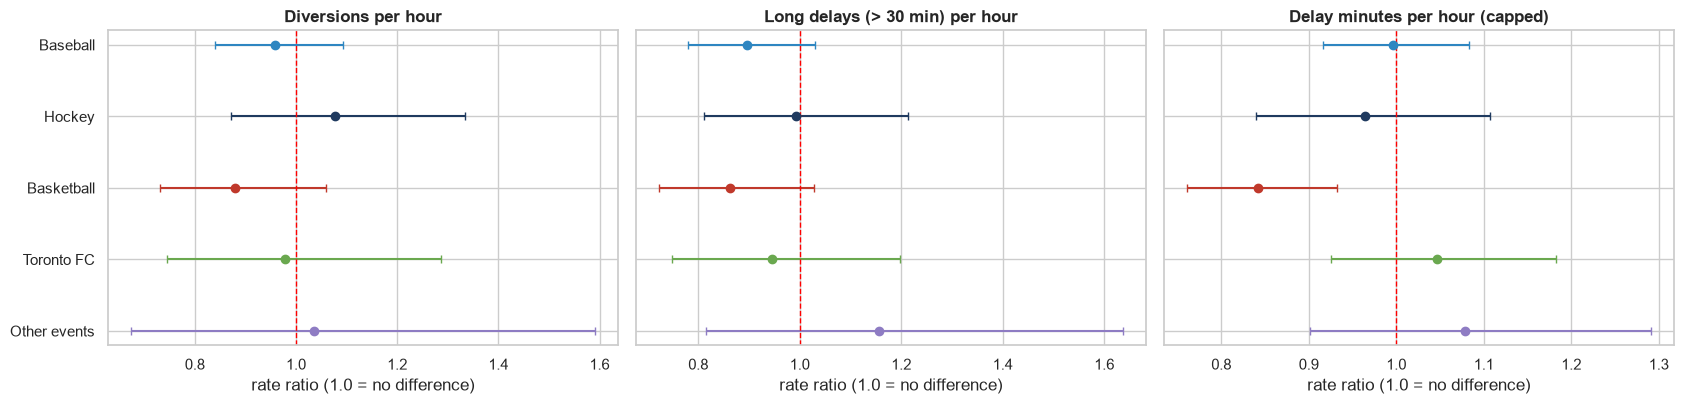

In [36]:
OUTCOME_LABELS = {"n_diversion": "Diversions per hour", "n_long_delays": "Long delays (> 30 min) per hour", "delay_minutes": "Delay minutes per hour (capped)"}
fits = {col: fit_poisson(model_data, col, main_rhs) for col in OUTCOME_LABELS}
outcome_rr = {col: rate_ratios(res).loc[list(EVENT_FLAGS)].rename(index=EVENT_FLAGS) for col, res in fits.items()}
print({OUTCOME_LABELS[c]: f"mean {model_data[c].mean():.2f} an hour, {(model_data[c] == 0).mean():.0%} of hours are zero" for c in OUTCOME_LABELS})

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2), sharey=True)
for ax, (col, label) in zip(axes, OUTCOME_LABELS.items()):
    t = outcome_rr[col]
    y = np.arange(len(t))[::-1]
    for yi, (name, row) in zip(y, t.iterrows()):
        ax.errorbar(row["rate_ratio"], yi, xerr=[[row["rate_ratio"] - row["lo"]], [row["hi"] - row["rate_ratio"]]], fmt="o", color=GROUP_COLORS[name], capsize=3)
    ax.axvline(1, color="red", ls="--", lw=1)
    ax.set_yticks(y)
    ax.set_yticklabels(t.index)
    ax.set(title=label, xlabel="rate ratio (1.0 = no difference)")
plt.tight_layout()
pd.DataFrame({OUTCOME_LABELS[c]: [f"{r:.2f} ({lo:.2f} to {hi:.2f})" for r, lo, hi in zip(t["rate_ratio"], t["lo"], t["hi"])] for c, t in outcome_rr.items()},
             index=list(EVENT_FLAGS.values()))

**How to read it:** the same plot as Step 3 for three outcomes. Dots are rate ratios, lines are 95% intervals, the red line is "no difference".

**What stands out:**
- **Diversions:** every interval includes 1.0. Baseball 0.96 (0.84 to 1.09), hockey 1.08 (0.87 to 1.33), basketball 0.88 (0.73 to 1.06), Toronto FC 0.98 (0.74 to 1.29), other events 1.04 (0.67 to 1.59). **No type of event raises diversions.** The intervals are wide because diversions are rare.
- **Long delays (over 30 minutes):** all below or around 1, none clear. Baseball 0.90 (0.78 to 1.03), basketball 0.86 (0.72 to 1.03).
- **Delay minutes:** **basketball is the only clear difference, 0.84 (0.76 to 0.93)**, the same dip as in Step 3. Baseball is at 1.00, hockey 0.96, Toronto FC 1.05, other events 1.08, all inside chance.

**What it means:** event hours do not have more diversions, longer delays or more delay minutes. Basketball hours have less delay time, and that is the only result that stands out.

### 5.2 What does that mean per event hour?
Expected without the event (from the model) vs actual, for each outcome.

In [37]:
rows = []
for col, label in OUTCOME_LABELS.items():
    expected_no_event = fits[col].predict(no_event)
    for flag, name in EVENT_FLAGS.items():
        sel = model_data[flag] == 1
        rows.append({"outcome": label, "event": name, "expected without event": expected_no_event[sel].mean(), "actual": model_data.loc[sel, col].mean()})
per_hour = pd.DataFrame(rows)
per_hour["difference"] = per_hour["actual"] - per_hour["expected without event"]
per_hour["difference (%)"] = per_hour["difference"] / per_hour["expected without event"] * 100
per_hour.pivot(index="event", columns="outcome", values="difference (%)").round(1).loc[list(EVENT_FLAGS.values())]

outcome,Delay minutes per hour (capped),Diversions per hour,Long delays (> 30 min) per hour
event,,,
Baseball,-0.5,-4.2,-10.5
Hockey,-3.4,7.3,-2.0
Basketball,-15.8,-12.3,-14.4
Toronto FC,4.1,-2.4,-8.1
Other events,7.3,1.5,10.0


**How to read it:** the difference between what happened and what the model expects without the event, as a percentage. This is the same as the rate ratios above, in more everyday terms.

**What stands out:**

| | Delay minutes | Diversions | Long delays |
|---|---|---|---|
| Baseball | -0.5% | -4.2% | -10.5% |
| Hockey | -3.4% | +7.3% | -2.0% |
| Basketball | **-15.8%** | -12.3% | -14.4% |
| Toronto FC | +4.1% | -2.4% | -8.1% |
| Other events | +7.3% | +1.5% | +10.0% |

Only basketball is consistently lower on all three (12% to 16%), and only its delay minutes are statistically clear. The positive numbers for other events rest on 93 hours.

### 5.3 Does the diversion result hold up?
The diversion model is re-run after removing hours that could drive it: the **5 evenings with the most diversions**, evenings with **recent snow**, and both.

Five evenings with the most diversions: {'2026-09-02': 55, '2026-01-15': 26, '2025-04-29': 25, '2025-08-31': 24, '2025-10-21': 24}


,Baseball,Hockey,Basketball,Toronto FC,Other events
main (all hours),0.959,1.078,0.880,0.979,1.036
without the 5 biggest diversion days,0.981,1.022,0.895,1.030,1.088
without recent snow (3-day snow <= 2 cm),0.941,1.095,0.824,0.982,1.008
without both,0.964,0.994,0.831,1.041,1.059


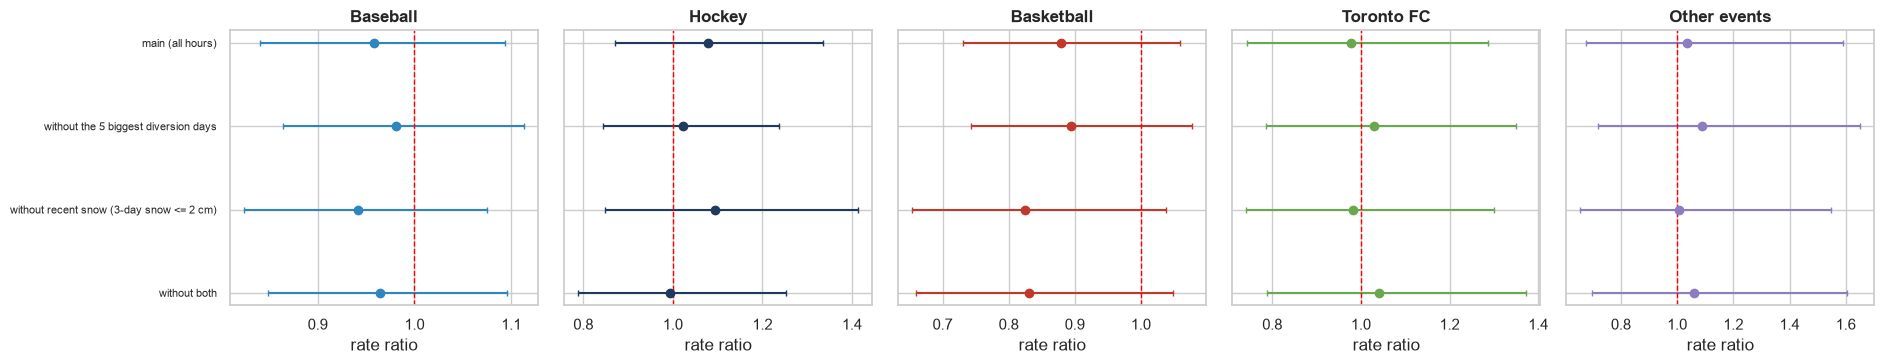

In [38]:
top_days = model_data.groupby("evening_date")["n_diversion"].sum().nlargest(5)
print("Five evenings with the most diversions:", {d.strftime("%Y-%m-%d"): int(n) for d, n in top_days.items()})
CHECKS = {
    "main (all hours)": pd.Series(True, index=model_data.index),
    "without the 5 biggest diversion days": ~model_data["evening_date"].isin(top_days.index),
    "without recent snow (3-day snow <= 2 cm)": ~model_data["snowy"],
    "without both": ~model_data["evening_date"].isin(top_days.index) & ~model_data["snowy"],
}


def rhs_without_constants(data, rhs):
    """Drop yes/no controls that never vary in the subset (they cannot be estimated)."""
    for term in ["snow_day", "snow3_over5", "heavy_rain", "is_holiday", "after_coding_change", "multi_event_day"]:
        if data[term].nunique() < 2:
            rhs = rhs.replace(f" + {term}", "")
    return rhs


check_rr = {}
for name, mask in CHECKS.items():
    subset = model_data[mask]
    result = fit_poisson(subset, "n_diversion", rhs_without_constants(subset, main_rhs))
    check_rr[name] = rate_ratios(result).loc[list(EVENT_FLAGS)].rename(index=EVENT_FLAGS)

fig, axes = plt.subplots(1, 5, figsize=(19, 3.8), sharey=True)
labels = list(CHECKS)
ypos = np.arange(len(labels))[::-1]
for ax, group in zip(axes, EVENT_FLAGS.values()):
    for yi, name in zip(ypos, labels):
        row = check_rr[name].loc[group]
        ax.errorbar(row["rate_ratio"], yi, xerr=[[row["rate_ratio"] - row["lo"]], [row["hi"] - row["rate_ratio"]]], fmt="o", color=GROUP_COLORS[group], capsize=2)
    ax.axvline(1, color="red", ls="--", lw=1)
    ax.set(title=group, xlabel="rate ratio")
axes[0].set_yticks(ypos)
axes[0].set_yticklabels(labels, fontsize=8)
plt.tight_layout()
pd.DataFrame({name: t["rate_ratio"] for name, t in check_rr.items()}).T.round(3)

**How to read it:** the diversion model for each event type, re-run after dropping the five evenings with the most diversions (2026-09-02 with 55, 2026-01-15 with 26, 2025-04-29, 2025-08-31 and 2025-10-21), evenings with recent snow, and both.

**What stands out:** **the results hardly move**. Baseball stays 0.94 to 0.98, Toronto FC 0.98 to 1.04, other events 1.01 to 1.09, hockey 0.99 to 1.10. **Basketball is 0.82 to 0.90** in every version, lower than the main 0.88 when snow evenings are dropped.

**What it means:** a few extreme days are not driving the diversion results. No type of event looks like a diversion risk, whichever hours we keep.

### 5.4 What does chance look like for diversions? Fake events
Same idea as 2.11: every real event is moved to a random day with no event and the same weekday (same hours), and the ratio of diversions to the usual is computed.
Repeated 1,000 times. The red line is the real ratio (the simple matched ratio from Step 2, now for diversions).

,real ratio,fake: mean,fake 2.5%,fake 97.5%,share of fake as far from 1
group,,,,,
Baseball,0.921,0.996,0.887,1.127,0.202
Hockey,1.024,1.009,0.826,1.234,0.818
Basketball,0.829,0.970,0.800,1.215,0.112
Toronto FC,0.839,1.038,0.764,1.426,0.305
Other events,0.984,0.997,0.656,1.536,0.968
All events,0.918,0.997,0.914,1.085,0.061


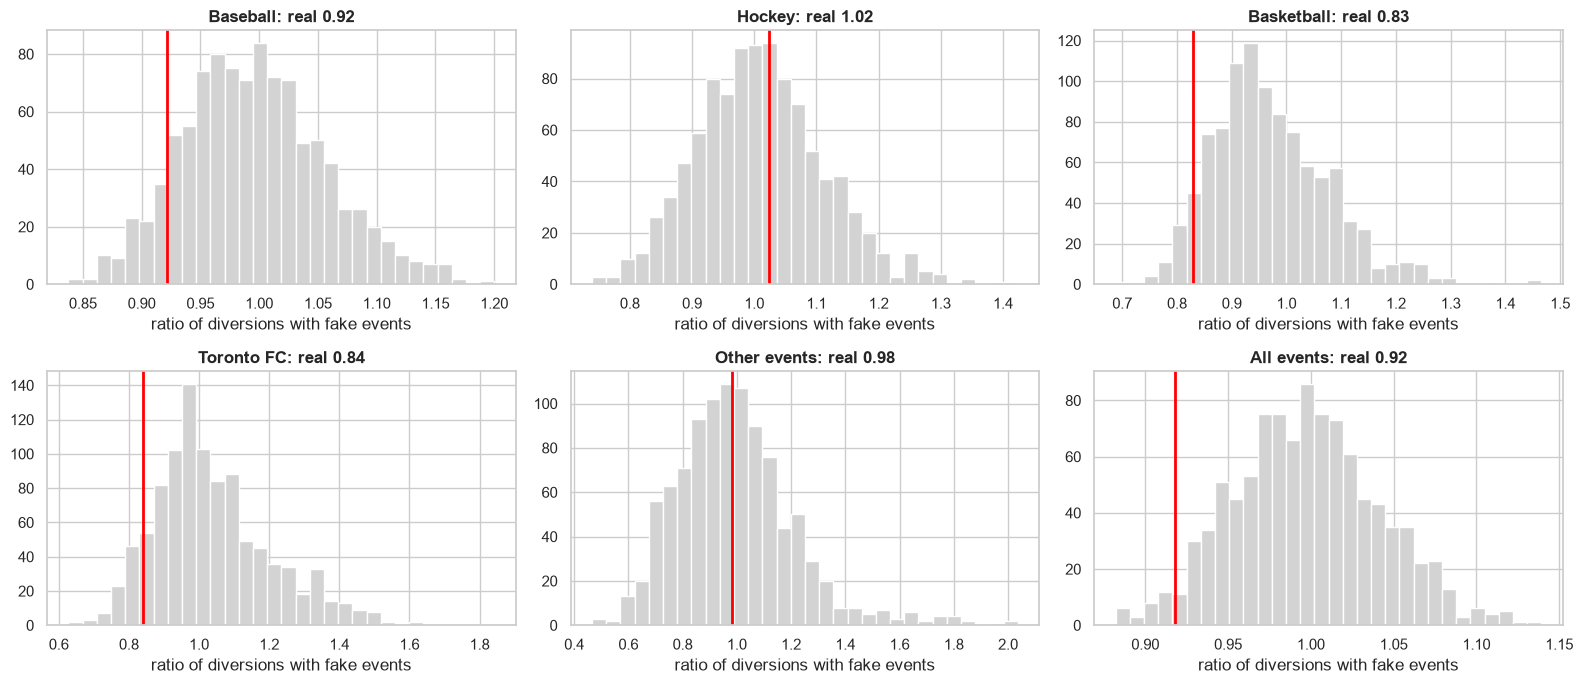

In [39]:
def placebo_ratios(outcome, n_draws=1000, seed=11):
    """Real and fake-event ratios (observed / usual for the same weekday and hour) for one outcome, by group."""
    rng = np.random.default_rng(seed)
    expected = add_expected(model_hours, SLOT168, outcome)["expected"].to_numpy()
    observed = model_hours[outcome].to_numpy()
    rows_of_ev = ev["row"].to_numpy()
    names = group_names + ["all"]
    real_ratio, fake_ratio = {}, {g: np.empty(n_draws) for g in names}
    for g in names:
        sel = np.ones(len(ev), bool) if g == "all" else hour_group == g
        real_ratio[g] = observed[rows_of_ev[sel]].sum() / expected[rows_of_ev[sel]].sum()
    wd_codes = windows["weekday"].to_numpy()
    for b in range(n_draws):
        pick = (rng.random(len(windows)) * cand_len[wd_codes]).astype(int)
        target = cand[wd_codes, pick][hour_win] + hour_off.astype("timedelta64[h]")
        pos = mh_idx.get_indexer(pd.DatetimeIndex(target))
        ok = pos >= 0
        ok[ok] = ~in_window_all[pos[ok]]
        for g in names:
            sel = ok if g == "all" else ok & (hour_group == g)
            fake_ratio[g][b] = observed[pos[sel]].sum() / expected[pos[sel]].sum()
    return real_ratio, fake_ratio


real_div, fake_div = placebo_ratios("n_diversion")
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
rows = []
for ax, g in zip(axes.ravel(), group_names + ["all"]):
    name = SPORT_NAMES.get(g, "All events")
    ax.hist(fake_div[g], bins=30, color="lightgray")
    ax.axvline(real_div[g], color="red", lw=2)
    ax.set(title=f"{name}: real {real_div[g]:.2f}", xlabel="ratio of diversions with fake events")
    rows.append({"group": name, "real ratio": real_div[g], "fake: mean": fake_div[g].mean(), "fake 2.5%": np.percentile(fake_div[g], 2.5),
                 "fake 97.5%": np.percentile(fake_div[g], 97.5), "share of fake as far from 1": (np.abs(fake_div[g] - 1) >= abs(real_div[g] - 1)).mean()})
plt.tight_layout()
pd.DataFrame(rows).set_index("group").round(3)

**How to read it:** the grey histograms are the diversion ratios when the events are moved to random days with no event (1,000 times). The red line is the real ratio.

**What stands out:**
- **Baseball (0.92), hockey (1.02), basketball (0.83), Toronto FC (0.84) and other events (0.98) are all within the fake range.** Chance gives ratios this far from 1 in 11% to 97% of the draws.
- **All events pooled: 0.92**, at the edge of the fake range (0.91 to 1.09), with 6% of fake draws as far from 1.

**What it means:** **no group of events differs from chance for diversions.** The pooled result points slightly down, but only just. Basketball's 0.83 does not stand out here, unlike for incidents and delay minutes.

### 5.5 Diversions near the venue (city events and sports)
The Step 4 model, with diversions as the outcome. Near-venue routes have very few diversions, so only the **two pooled flags** (sports, other city events) are used.

Near-venue diversions: 605 in the period, 178 in event hours, 13 in city-event hours | 94% of hours have none


quantity,Other routes,Extra near-venue effect,Near-venue routes
event,,,
"Other city events (parades, festivals, World Cup)",0.94 (0.57 to 1.53),2.22 (1.15 to 4.28),2.07 (1.17 to 3.67)
"Sports (baseball, hockey, basketball, Toronto FC)",0.95 (0.84 to 1.07),1.07 (0.84 to 1.36),1.01 (0.80 to 1.27)


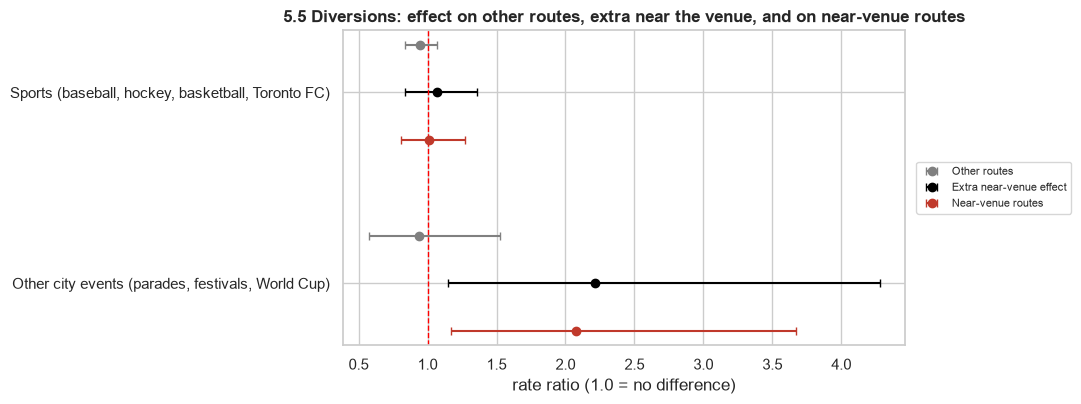

In [40]:
is_div = incidents["code"].eq("MFDV")
div_near, div_other = hourly_count(is_div & near1), hourly_count(is_div & other1)
print(f"Near-venue diversions: {int(div_near.sum())} in the period, {int(div_near[model_data['in_event_window'].to_numpy() == 1].sum())} in event hours, "
      f"{int(div_near[model_data['win_other'].to_numpy() == 1].sum())} in city-event hours | {(div_near == 0).mean():.0%} of hours have none")
near_div = stack(div_near, div_other)
res_div = fit_near(near_div, FLAGS_MAIN)
effects_div = near_effects(res_div, FLAGS_MAIN, NAMES_MAIN)
plot_effects(effects_div, "5.5 Diversions: effect on other routes, extra near the venue, and on near-venue routes")
effects_table(effects_div)

**How to read it:** the Step 4 model with diversions as the outcome. Grey = other routes, black = extra near the venue, red = near-venue routes.

**What stands out:**
- **Sports: nothing.** Near-venue routes are at **1.01 (0.80 to 1.27)**, with an extra effect of 1.07 (0.84 to 1.36).
- **Other city events: 2.07 (1.17 to 3.67) on near-venue routes, extra effect 2.22 (1.15 to 4.28).** That looks like a doubling.

**But look at the counts:** near-venue routes had **605 diversions in the whole period**, 94% of hours have none, and **only 13 were in city-event hours**. A result built on 13 diversions is close to an anecdote.

### 5.6 Fake city events for the near-venue diversions
The 12 city events are moved to random event-free days (same weekday and hours), the model is refitted, 200 times.

Extra near-venue effect: fake range 0.32 to 2.20, share as high as the real one: 0.025
Near-venue routes: fake range 0.29 to 2.30, share as high as the real one: 0.060


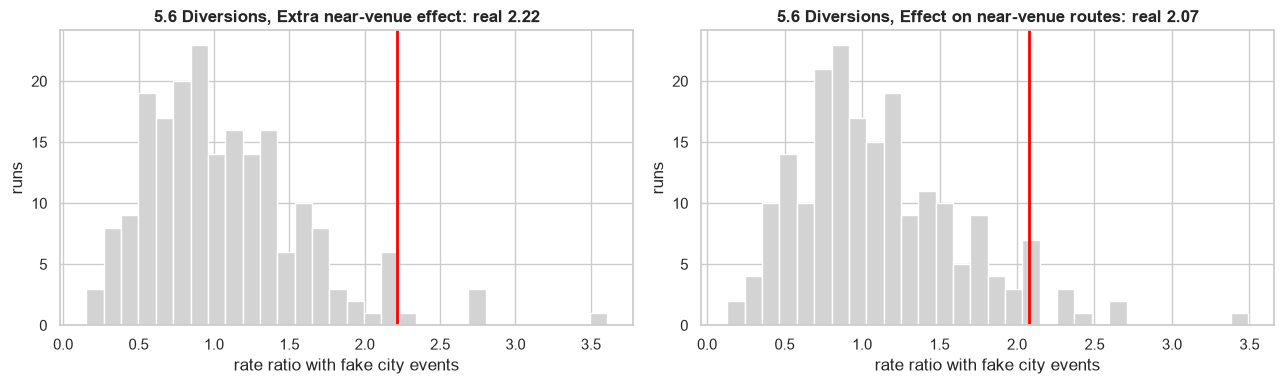

In [41]:
def fake_city_effect_counts(rng, near_counts, other_counts):
    pick = (rng.random(len(other_windows)) * cand_len[o_wd]).astype(int)
    target = cand[o_wd, pick][o_win] + o_off
    pos = mh_pos.get_indexer(pd.DatetimeIndex(target))
    pos = pos[pos >= 0]
    pos = pos[~real_window[pos]]
    data = model_data.copy()
    data["win_other"] = 0
    data.loc[data.index[pos], "win_other"] = 1
    res = fit_near(stack(near_counts, other_counts, data=data), FLAGS_MAIN)
    eff = near_effects(res, ["win_other"]).set_index("quantity")["rate_ratio"]
    return eff["Extra near-venue effect"], eff["Near-venue routes"]


rng = np.random.default_rng(21)
fake_div_runs = np.array([fake_city_effect_counts(rng, div_near, div_other) for _ in range(200)])
real_extra_div = effects_div[(effects_div["event"] == NAMES_MAIN["win_other"]) & (effects_div["quantity"] == "Extra near-venue effect")]["rate_ratio"].iloc[0]
real_near_div = effects_div[(effects_div["event"] == NAMES_MAIN["win_other"]) & (effects_div["quantity"] == "Near-venue routes")]["rate_ratio"].iloc[0]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, values, real_value, title in zip(axes, fake_div_runs.T, [real_extra_div, real_near_div], ["Extra near-venue effect", "Effect on near-venue routes"]):
    ax.hist(values, bins=30, color="lightgray")
    ax.axvline(real_value, color="red", lw=2)
    ax.set(title=f"5.6 Diversions, {title}: real {real_value:.2f}", xlabel="rate ratio with fake city events", ylabel="runs")
plt.tight_layout()
print(f"Extra near-venue effect: fake range {np.percentile(fake_div_runs[:, 0], 2.5):.2f} to {np.percentile(fake_div_runs[:, 0], 97.5):.2f}, share as high as the real one: {(fake_div_runs[:, 0] >= real_extra_div).mean():.3f}")
print(f"Near-venue routes: fake range {np.percentile(fake_div_runs[:, 1], 2.5):.2f} to {np.percentile(fake_div_runs[:, 1], 97.5):.2f}, share as high as the real one: {(fake_div_runs[:, 1] >= real_near_div).mean():.3f}")

**How to read it:** the 12 city events moved to random event-free days, the model refitted 200 times. The red line is the real result.

**What stands out:**
- **Extra near-venue effect:** the fake range is **0.32 to 2.20**, so chance alone gives anything from a 70% drop to a doubling. The real 2.22 is at the very top: **2.5% of fake runs are as high**.
- **Effect on near-venue routes:** fake range 0.29 to 2.30, and **6%** of fake runs are as high as the real 2.07.
- The fake range is far wider than the model's interval (1.15 to 4.28), so the model overstates how sure we are.

**What it means:** with 13 diversions, this is not a reliable result. It matches the pattern from Step 4 (more incidents near the venue during city events), but diversions alone are too few to confirm it.

### Step 5 takeaways
- **Event hours do not have more diversions.** Baseball 0.96, hockey 1.08, basketball 0.88, Toronto FC 0.98, other events 1.04, all inside chance. This holds without the five biggest diversion days and without snow evenings (the results move by at most about 0.08).
- **Long delays and delay minutes point slightly down, not up.** The one clear result is **basketball delay minutes, 0.84 (0.76 to 0.93)**, about 16% less, the same dip as in Steps 2 and 3.
- **Fake events agree:** for diversions no group differs from chance (11% to 97% of fake runs match). All events pooled: 0.92, borderline (6%).
- **Near venues, sports show nothing** for diversions (1.01, 0.80 to 1.27).
- **Near venues, city events show a doubling (2.07)**, but it rests on **13 diversions** and the fake events range from 0.3 to 2.3. It fits the Step 4 pattern but is not reliable on its own.

**What this adds to the picture:** across incidents, diversions, long delays and delay minutes, **sports events do not make bus service worse**. Basketball hours are, if anything, lighter. The only consistent hint of extra trouble is during **parades, the World Cup and festivals on the routes near the venue**, which rests on 12 events.

**Next:** the cause-group split (to check the basketball security dip), and a short summary of what we can conclude.

## Step 6. Cause groups

Step 2 suggested the basketball dip comes mostly from fewer **security** and **miscellaneous** incidents. This step tests that with the full model.
The same Poisson model is run on incidents in each of the four cause groups: **Equipment** (the bus itself), **Operator** (staff), **Security** (patrons, safety) and **Miscellaneous** (diversions, shuttles, illness, weather and more).

### 6.1 Main model by cause group

{'Equipment': 'mean 2.56 an hour', 'Operator': 'mean 1.95 an hour', 'Security': 'mean 0.52 an hour', 'Miscellaneous': 'mean 2.94 an hour'}


,Equipment,Operator,Security,Miscellaneous
Baseball,1.02 (0.95 to 1.09),1.09 (1.00 to 1.17),1.00 (0.91 to 1.10),1.02 (0.94 to 1.10)
Hockey,1.01 (0.93 to 1.10),0.97 (0.85 to 1.10),0.91 (0.80 to 1.05),0.94 (0.82 to 1.08)
Basketball,0.97 (0.87 to 1.07),0.87 (0.76 to 0.99),0.85 (0.74 to 0.98),0.92 (0.79 to 1.06)
Toronto FC,1.07 (0.97 to 1.19),1.07 (0.93 to 1.24),1.11 (0.94 to 1.32),1.11 (0.94 to 1.30)
Other events,0.97 (0.80 to 1.18),1.03 (0.83 to 1.28),0.88 (0.59 to 1.30),0.92 (0.76 to 1.12)


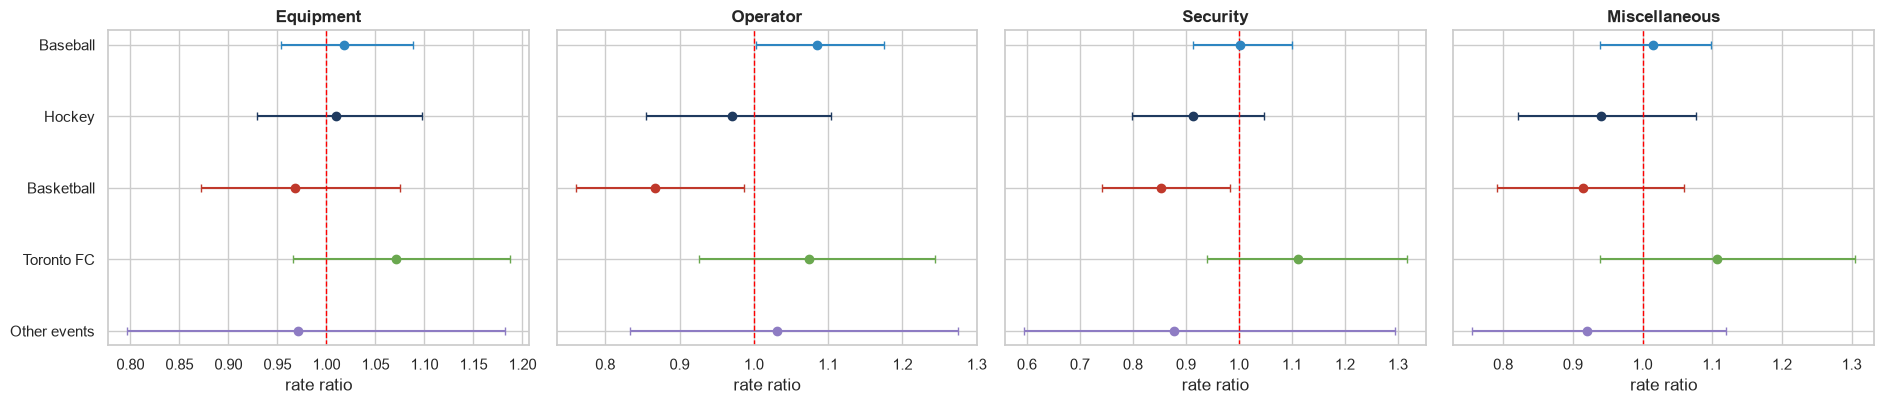

In [42]:
CAUSE_LABELS = {"n_cause_Equipment": "Equipment", "n_cause_Operator": "Operator", "n_cause_Security": "Security", "n_cause_Miscellaneous": "Miscellaneous"}
cause_fits = {col: fit_poisson(model_data, col, main_rhs) for col in CAUSE_LABELS}
cause_rr = {col: rate_ratios(res).loc[list(EVENT_FLAGS)].rename(index=EVENT_FLAGS) for col, res in cause_fits.items()}
print({label: f"mean {model_data[col].mean():.2f} an hour" for col, label in CAUSE_LABELS.items()})

fig, axes = plt.subplots(1, 4, figsize=(19, 4.2), sharey=True)
for ax, (col, label) in zip(axes, CAUSE_LABELS.items()):
    t = cause_rr[col]
    y = np.arange(len(t))[::-1]
    for yi, (name, row) in zip(y, t.iterrows()):
        ax.errorbar(row["rate_ratio"], yi, xerr=[[row["rate_ratio"] - row["lo"]], [row["hi"] - row["rate_ratio"]]], fmt="o", color=GROUP_COLORS[name], capsize=3)
    ax.axvline(1, color="red", ls="--", lw=1)
    ax.set_yticks(y)
    ax.set_yticklabels(t.index)
    ax.set(title=label, xlabel="rate ratio")
plt.tight_layout()
pd.DataFrame({label: [f"{r:.2f} ({lo:.2f} to {hi:.2f})" for r, lo, hi in zip(cause_rr[col]["rate_ratio"], cause_rr[col]["lo"], cause_rr[col]["hi"])]
              for col, label in CAUSE_LABELS.items()}, index=list(EVENT_FLAGS.values()))

**How to read it:** the same plot as Step 3, one panel per cause group. Dots are rate ratios, lines are 95% intervals.

**What stands out:**
- **Basketball: operator 0.87 (0.76 to 0.99) and security 0.85 (0.74 to 0.98)**, both clearly below 1. Miscellaneous is 0.92 (0.79 to 1.06) and equipment 0.97 (0.87 to 1.07), no clear change.
- **Baseball: operator 1.09 (1.00 to 1.17)**, a small rise that just reaches the edge of chance. Equipment, security and miscellaneous are at 1.0.
- **Hockey:** security 0.91 and miscellaneous 0.94, not clear. **Toronto FC:** 1.07 to 1.11 in every group, none clear.
- **Other events:** nothing clear.

**What it means:** the basketball dip is **spread over staff and security incidents** (operator and security), not over equipment. In Step 2, without controls, the operator drop was not visible (0.98); it appears once month, holiday and weather are held equal.

### 6.2 In incidents per event hour
What the model expects without the event vs what happened, per hour and as a percentage.

In [43]:
rows = []
for col, label in CAUSE_LABELS.items():
    expected_no_event = cause_fits[col].predict(no_event)
    for flag, name in EVENT_FLAGS.items():
        sel = model_data[flag] == 1
        rows.append({"cause": label, "event": name, "expected": expected_no_event[sel].mean(), "actual": model_data.loc[sel, col].mean()})
cause_hour = pd.DataFrame(rows)
cause_hour["difference per hour"] = cause_hour["actual"] - cause_hour["expected"]
cause_hour["difference (%)"] = cause_hour["difference per hour"] / cause_hour["expected"] * 100
print("Difference in incidents per hour (actual - expected without the event):")
display_table = cause_hour.pivot(index="event", columns="cause", values="difference per hour").loc[list(EVENT_FLAGS.values())].round(2)
display_table

Difference in incidents per hour (actual - expected without the event):


cause,Equipment,Miscellaneous,Operator,Security
event,,,,
Baseball,0.05,0.04,0.15,-0.00
Hockey,0.03,-0.15,-0.03,-0.04
Basketball,-0.06,-0.22,-0.23,-0.08
Toronto FC,0.17,0.29,0.17,0.05
Other events,-0.06,-0.23,0.13,-0.07


**How to read it:** incidents per event hour, actual minus what the model expects without the event. Negative = fewer than expected.

**What stands out:** for **basketball** the shortfall is about **0.6 incidents an hour in total**: 0.23 fewer operator incidents, 0.22 fewer miscellaneous, 0.08 fewer security and 0.06 fewer equipment. **Toronto FC** is +0.17 equipment, +0.29 miscellaneous, +0.17 operator and +0.05 security, which adds up to the borderline +9% that does not hold up (see notebook 04). Baseball's only notable number is +0.15 operator incidents.

**What it means:** in incident counts, the biggest part of the basketball dip is operator and miscellaneous, even though the security *share* drops the most.

### 6.3 Fake events for each cause group
The same check as 2.11, per cause group. Is any group's ratio different from what random days give?

In [44]:
cause_placebo = {}
for col, label in CAUSE_LABELS.items():
    real_c, fake_c = placebo_ratios(col, n_draws=500, seed=3)
    cause_placebo[label] = {g: (real_c[g], np.percentile(fake_c[g], 2.5), np.percentile(fake_c[g], 97.5), (np.abs(fake_c[g] - 1) >= abs(real_c[g] - 1)).mean())
                            for g in group_names + ["all"]}
placebo_table = pd.DataFrame({label: {SPORT_NAMES.get(g, "All events"): f"{v[0]:.2f} (fake {v[1]:.2f}-{v[2]:.2f}; p={v[3]:.2f})" for g, v in d.items()}
                              for label, d in cause_placebo.items()})
placebo_table

,Equipment,Operator,Security,Miscellaneous
Baseball,0.96 (fake 0.95-1.06; p=0.14),0.99 (fake 0.92-1.08; p=0.75),1.02 (fake 0.90-1.07; p=0.62),1.02 (fake 0.94-1.08; p=0.61)
Hockey,0.98 (fake 0.91-1.09; p=0.74),1.02 (fake 0.88-1.15; p=0.72),0.87 (fake 0.85-1.16; p=0.08),0.92 (fake 0.90-1.13; p=0.12)
Basketball,0.96 (fake 0.91-1.09; p=0.34),0.98 (fake 0.87-1.14; p=0.80),0.77 (fake 0.86-1.14; p=0.00),0.86 (fake 0.89-1.11; p=0.01)
Toronto FC,0.97 (fake 0.88-1.13; p=0.58),0.81 (fake 0.81-1.19; p=0.05),1.07 (fake 0.78-1.18; p=0.53),1.05 (fake 0.85-1.16; p=0.56)
Other events,0.95 (fake 0.83-1.19; p=0.64),0.97 (fake 0.73-1.35; p=0.88),0.97 (fake 0.69-1.40; p=0.83),0.92 (fake 0.76-1.26; p=0.57)
All events,0.96 (fake 0.96-1.04; p=0.06),0.97 (fake 0.95-1.06; p=0.36),0.94 (fake 0.93-1.05; p=0.10),0.97 (fake 0.95-1.05; p=0.25)


**How to read it:** the simple matched ratio (weekday and hour only) for each cause group, next to the range that fake events give (2.5% to 97.5%) and the share of fake runs as far from 1 as the real one (`p`).

**What stands out:**
- **Basketball security: 0.77 (fake range 0.86 to 1.14, p = 0.00)** and **basketball miscellaneous 0.86 (p = 0.01)** are outside chance. Basketball operator (0.98) and equipment (0.96) are not.
- **Hockey security 0.87 (p = 0.08)** is borderline.
- **Toronto FC operator 0.81 (p = 0.05)** looks low here but is 1.07 in the regression, which shows how unstable Toronto FC is.
- **All events pooled:** equipment 0.96 (p = 0.06), everything else p of 0.10 or more.

**What it means:** the two methods agree that basketball has **fewer security incidents**. They differ on operator (clear only after controls) and miscellaneous (clear only without controls), so the **security drop is the steadier part** of the basketball dip.

## Step 7. Conclusions

This step puts every result together: one picture of all outcomes, then the answer to each research question.

### 7.1 One picture: every outcome and event type

,Incidents,Diversions,Long delays,Delay minutes,Equipment,Operator,Security,Miscellaneous
Baseball,1.03,0.96,0.90,1.00,1.02,1.09,1.00,1.02
Hockey,0.96,1.08,0.99,0.96,1.01,0.97,0.91,0.94
Basketball,0.91,0.88,0.86,0.84,0.97,0.87,0.85,0.92
Toronto FC,1.09,0.98,0.95,1.05,1.07,1.07,1.11,1.11
Other events,0.95,1.04,1.16,1.08,0.97,1.03,0.88,0.92


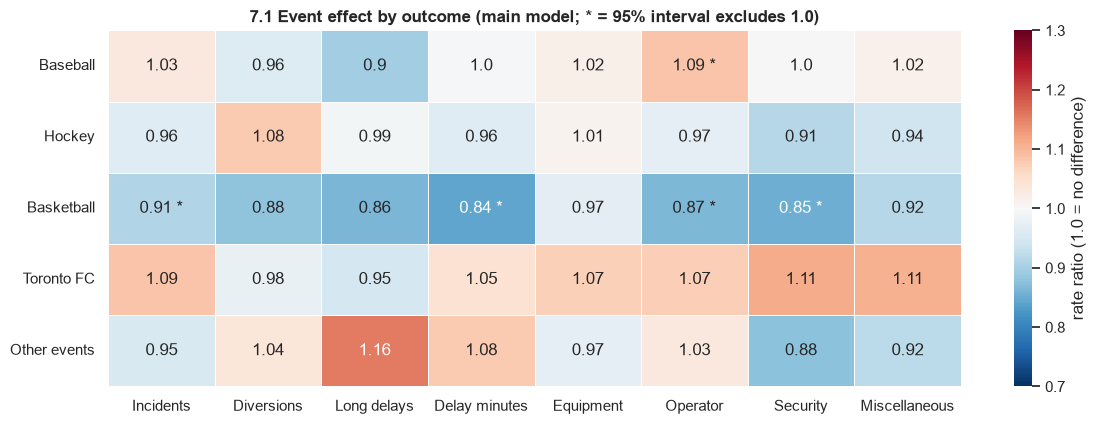

In [45]:
all_models = {"Incidents": main, **{OUTCOME_LABELS[c].split(" per")[0].split(" (")[0]: r for c, r in fits.items()}, **{label: cause_fits[col] for col, label in CAUSE_LABELS.items()}}
columns = ["Incidents", "Diversions", "Long delays", "Delay minutes", "Equipment", "Operator", "Security", "Miscellaneous"]
ratio_grid = pd.DataFrame(index=list(EVENT_FLAGS.values()), columns=columns, dtype=float)
clear_grid = pd.DataFrame(False, index=ratio_grid.index, columns=columns)
for name in columns:
    t = rate_ratios(all_models[name]).loc[list(EVENT_FLAGS)].rename(index=EVENT_FLAGS)
    ratio_grid[name] = t["rate_ratio"]
    clear_grid[name] = (t["lo"] > 1) | (t["hi"] < 1)

fig, ax = plt.subplots(figsize=(12, 4.4))
labels = ratio_grid.round(2).astype(str) + np.where(clear_grid, " *", "")
sns.heatmap(ratio_grid, annot=labels, fmt="", cmap="RdBu_r", center=1, vmin=0.7, vmax=1.3, linewidths=0.5, ax=ax, cbar_kws={"label": "rate ratio (1.0 = no difference)"})
ax.set(title="7.1 Event effect by outcome (main model; * = 95% interval excludes 1.0)", xlabel="", ylabel="")
plt.tight_layout()
ratio_grid.round(2)

**How to read it:** rows are event types and columns are outcomes; each cell is the rate ratio from the main model. Red is above 1, blue below. A star means the 95% interval excludes 1.0.

**What stands out:**
- **Only five cells carry a star.** Four are **basketball** (incidents 0.91, delay minutes 0.84, operator incidents 0.87, security incidents 0.85), and one is **baseball operator incidents (1.09)**.
- **Nothing for diversions, long delays or equipment**, in any group.
- **Toronto FC is above 1 in most columns (1.05 to 1.11) but with no star**, and it is the group we showed to be unstable.
- **Other events** have the widest ranges (for example long delays 1.16) with no clear effect.

**What it means:** there is **no event type that clearly makes bus service worse**. The one clear and consistent pattern is that basketball hours are lighter.

### 7.2 The answers to the research questions

**1. On days and hours with major events, are bus delay incidents more frequent or longer than on comparable days and hours without events?**
**No.** With weekday, hour, month, weather, holiday and coding period held equal, baseball hours are at 1.03 (0.98 to 1.08), hockey at 0.96, Toronto FC at 1.09 (not reliable), other events at 0.95.
Delays are not longer either: long delays (0.86 to 1.16) and delay minutes (0.84 to 1.08) show no rise. Basketball hours are **lower** (0.91 for incidents, 0.84 for delay minutes).

**2. Which event types and venues have the largest effect?**
**Basketball (Scotiabank Arena) is the only clear effect, and it is a decrease:** about 9% fewer incidents, 16% less delay time, about 0.6 fewer incidents an hour. Baseball at Rogers Centre (1.03) and hockey at Scotiabank Arena (0.96) are at "no difference".
Toronto FC at BMO Field shows a nominal rise (1.09), but it depends on how weekends are grouped (0.98 with each weekday separately) and fake Saturday events give about the same rise (see notebook 04), so we do **not** treat it as a finding.

**3. Is the effect concentrated on routes near the venue and in the hours around the event?**
**For sports, no.** Near-venue routes are at 1.01 (0.93 to 1.09), and flat before, during and after the game (1.00 to 1.02). It holds at 3 km and without night routes.
**For parades, the World Cup and festivals there is a possible rise on near-venue routes** (1.22, and 1.31 times the effect on other routes), but it rests on 93 hours from 12 events. In the fake-event check only 4.5% of fake runs match the extra effect and 14% match the near-venue effect, and a realistic interval for the extra effect is about 0.95 to 1.8. **Treat it as a lead, not a result.**

**4. Which causes increase?**
**No cause group increases clearly.** Diversions (`MFDV`), the cause most tied to road closures, are at 0.88 to 1.08 for every event type, and they hold without the five biggest diversion days and without snow. Parade holds (`MFPR`) are too rare to analyse (about 85 incidents), and `MFUS` cannot be used because its meaning changed twice.
Basketball hours have **fewer security (0.85) and operator (0.87) incidents**. The only small rise is baseball operator incidents (1.09, borderline).

### 7.3 What this does and does not say
- **What it supports:** major sports events in Toronto do not, on average, make TTC bus service worse in the hours around them, by any of the measures here. The effects found are small (up to 9%) next to a snow day (+22%), a hot day (+29%) or a holiday (-32%).
- **Why that may be:** TTC and the City may already plan for events (extra buses, planned diversions), or event traffic may affect road speed without leading to logged incidents. The data cannot tell which. It records **service incidents logged by staff**, not traffic or road speed.
- **What it cannot say:** it is not causal proof. It has no data on buses running, so it says nothing about the *cost* of event service. The city events (parades, World Cup, festivals) are few, so they stay a lead. Weather is one daily value from one station.
- **Robustness:** see `04_verification` for 21 checks and fake-event tests.